# JRT results: graded response model, model ladder and reliability

Display notebook for the manuscript. It fits nothing: it shows the CSV and figure
outputs of the R pipeline in `../R/` (`01_data_design.R` … `06_summary.R`, see
`../server/README.md` and `../AUDIT.md`) as labelled tables and figures,
so the manuscript can embed them. Re-execute it (seconds) after every pipeline run.
Objects whose source file does not exist yet show a placeholder line.

Numbers in the text come from these tables through the results-interpreter.

The rated products are the football actions; raters are the judges of judge response
theory. Raters with fewer than 15 ratings are excluded from the whole pipeline (decision
2026-10-22; see `results/data/excluded_raters.csv`). Short notes above each object say
what it shows; references are listed at the end.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Markdown

RES = Path("..").resolve() / "results"

def _missing(path):
    return Markdown(f"_Not available yet: `results/{path}` (run the R pipeline)._")

def read_res(path):
    f = RES / path
    return pd.read_csv(f) if f.exists() else None

def fmt_cell(v, digits=3, p_value=False):
    # Display formatting only: whole numbers without decimals, p-values in
    # scientific notation below .001, missing values as an en dash.
    if v is None or (isinstance(v, float) and pd.isna(v)) or (isinstance(v, str) and v in ("", "NA", "nan")):
        return "–"
    if isinstance(v, (bool, np.bool_)):
        return str(v)
    try:
        x = float(v)
    except (TypeError, ValueError):
        return str(v).replace("|", r"\|")  # a bare | would split the Markdown cell
    if p_value:
        return f"{x:.2e}" if x < 0.001 else f"{x:.3f}"
    if x.is_integer():
        return f"{int(x):,}"
    return f"{x:,.{digits}f}"

def tidy(df, digits=3):
    out = df.copy().astype(object)
    for col in out.columns:
        is_p = col == "p" or col.startswith("p_")
        out[col] = [fmt_cell(v, digits, is_p) for v in df[col]]
    return out

# Readable column headers for the manuscript tables (display only; the CSVs keep
# the code names). Unlisted names: underscores become spaces.
HEADERS = {
    "rater_id": "Rater", "n_ratings": "Ratings by rater", "ratings_per_product": "Ratings per product",
    "ratings_total": "Ratings (total)", "n_products": "Products", "n_raters": "Raters",
    "reason": "Reason", "quantity": "Quantity", "value": "Value", "estimate": "Estimate", "se": "SE",
    "ci_low": "95% CI lower", "ci_high": "95% CI upper", "note": "Note", "model": "Model",
    "n_categories_used": "Categories used", "missing_categories": "Missing categories",
    "internal_gap": "Internal gap", "method": "Method", "quadpts": "Quadrature points",
    "se_type": "SE type", "tol": "Tolerance", "converged": "Converged", "iterations": "Iterations",
    "information_matrix_pd": "Information matrix positive definite", "logLik": "Log-likelihood",
    "npar": "Parameters", "infit": "Infit", "outfit": "Outfit", "S_X2": "S-X²", "df_S_X2": "df",
    "p_S_X2": "p", "n_imputations": "Imputations", "rater_1": "Rater 1", "rater_2": "Rater 2",
    "n_common": "Shared products", "q3": "Q3", "q3_minus_mean": "Q3 minus mean Q3",
    "overlap_flag": "Overlap", "flag_q3": "Flagged", "statistic": "Statistic", "computable": "Computable",
    "rater_pairs": "Rater pairs", "rater_pairs_without_overlap": "Rater pairs without shared products",
    "info_weighted_area": "Information per rating", "theta_at_max": "θ at maximum",
    "info_max": "Maximum information", "share_weighted": "Share of panel information",
    "share_at_theta_-2": "Share at θ = −2", "share_at_theta_-1": "Share at θ = −1",
    "share_at_theta_+0": "Share at θ = 0", "share_at_theta_+1": "Share at θ = 1",
    "share_at_theta_+2": "Share at θ = 2", "n_draws": "Draws", "n_draws_rejected": "Draws rejected",
    "rel_post_mean": "Mean rel_post", "rel_post_median": "Median rel_post",
    "rel_info_mean": "Mean rel_info", "psd_mean": "Mean PSD", "software": "Software", "family": "Family",
    "delta_AIC": "ΔAIC", "delta_BIC": "ΔBIC", "delta_SABIC": "ΔSABIC", "comparison": "Comparison",
    "X2": "χ²", "df_expected_formula": "df if all categories used",
    "df_matches_formula": "df equal", "pearson": "Pearson r", "spearman": "Spearman ρ",
    "mean_abs_percentile_shift": "Mean percentile shift",
    "p95_abs_percentile_shift": "95th percentile of shift", "max_abs_percentile_shift": "Maximum shift",
    "share_products_changing_quintile": "Share changing quintile",
    "share_products_changing_quintile_by_2_or_more": "Share changing ≥ 2 quintiles",
    "final_data": "Final data", "all_raters": "All raters", "n_steps": "Steps", "ordered": "Ordered",
    "n_reversals": "Reversals", "steps": "Step parameters", "latent_variance": "Latent variance",
    "marginal_reliability": "Marginal reliability", "marginal_rxx_mirt": "marginal_rxx (mirt)",
    "empirical_rxx": "Empirical reliability", "index": "Index", "refers_to": "Refers to",
    "ci_or_note": "CI or note", "n_boot": "Bootstrap replications", "n_boot_failed": "Failed replications",
    "kendall_tau_b": "Kendall's τ-b", "share_discordant_pairs": "Share of pairs in reversed order",
    "mean_theta_range_same_raw_mean": "Mean θ̂ range at equal raw mean",
    "max_theta_range_same_raw_mean": "Maximum θ̂ range at equal raw mean",
    "k": "Ratings per product (k)", "empirical": "Empirical reliability [95% range]",
    "true_r2": "Squared correlation with true θ", "mean_rel_post": "Mean rel_post",
    "index_value": "Value",
}
for _k in range(1, 8):
    HEADERS[f"cat_{_k}"] = f"Category {_k}"

# Readable values for code names in table cells (display only).
VALUES = {"M1_RSM": "M1 (rating-scale MFRM)", "M2_PCM": "M2 (partial-credit MFRM)", "M3_GPCM": "M3 (GPCM)", "GRM": "GRM",
          "rm_facets_default_grid": "M1, sirt default grid", "pearson": "Pearson", "spearman": "Spearman"}

def pretty_values(df):
    out = df.copy()
    for col in out.columns:
        out[col] = [VALUES.get(v, v.replace("_", " ") if isinstance(v, str) and "_" in v and " " not in v else v)
                    for v in out[col]]
    return out

def pretty_headers(df):
    return df.rename(columns=lambda c: HEADERS.get(c, VALUES.get(c, c.replace("_", " "))))

def power_of_ten(x):
    # e.g. 1e-4 -> "10⁻⁴" (a string, so the number formatting leaves it alone)
    return "10" + str(int(round(np.log10(x)))).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))

def est_ci(d, est, low, high, digits=2):
    # "estimate [low, high]" in one cell, for compact tables.
    return [f"{e:.{digits}f} [{l:.{digits}f}, {h:.{digits}f}]" for e, l, h in zip(d[est], d[low], d[high])]

def est_se(d, cols, digits=2):
    # "estimate (SE)" in one cell, for compact parameter tables.
    out = d.copy()
    for c in cols:
        out[c] = [("–" if pd.isna(e) else f"{e:.{digits}f} ({s:.{digits}f})") for e, s in zip(d[c], d[f"{c}_se"])]
    return out.drop(columns=[f"{c}_se" for c in cols])

def show_table(path, fn=None, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    df = read_res(path)
    if df is None:
        return _missing(path)
    if fn is not None:
        df = fn(df)
    return Markdown(pretty_headers(pretty_values(tidy(df, digits))).to_markdown(index=False, disable_numparse=True))

def show_png(path, width=8):
    f = RES / path
    if not f.exists():
        return _missing(path)
    img = mpimg.imread(f)
    # One figure pixel per image pixel: no resampling of the R figure.
    dpi = img.shape[1] / width
    fig, ax = plt.subplots(figsize=(width, width * img.shape[0] / img.shape[1]), dpi=dpi)
    ax.imshow(img)
    ax.axis("off")
    fig.tight_layout(pad=0)
    plt.show()

## 1. Data and design

**Design.** Size and coverage of the products × raters matrix that every model uses. The design is incomplete: each product is rated by a few raters only, and missing ratings are left out of the likelihood, not imputed. A connected design (one component) is required so that all raters and products lie on one scale (Eckes, 2015).

In [2]:
#| label: tbl-design-summary
#| tbl-cap: "Data basis shared by all models: ratings, products, raters, coverage of the product x rater matrix and connectivity of the design."
show_table("data/design_summary.csv", lambda d: d[d["quantity"] != "data_fingerprint"])

| Quantity                                  | Value            |
|:------------------------------------------|:-----------------|
| n ratings                                 | 7,820            |
| n products                                | 3,668            |
| n raters                                  | 19               |
| min_ratings_per_rater (exclusion cut-off) | 15               |
| raters excluded                           | R20;R21;R22      |
| ratings excluded                          | 24               |
| products dropped                          | 1                |
| n categories                              | 7                |
| scale                                     | 1-7              |
| internal coding                           | rating - 1 (0-6) |
| ratings per product mean                  | 2.132            |
| ratings per product median                | 2                |
| ratings per product min                   | 1                |
| ratings per product max                   | 10               |
| ratings per product harmonic mean         | 1.726            |
| products with 1 rating                    | 897              |
| ratings per rater min                     | 50               |
| ratings per rater max                     | 1,174            |
| matrix fill                               | 0.112            |
| n components                              | 1                |
| rater pairs total                         | 171              |
| rater pairs without overlap               | 17               |
| rater pairs overlap median                | 13               |
| raters with category gaps                 | 5                |
| raters with internal gap                  | 0                |
| duplicate pairs resolved in 00            | 12               |
| duplicate pairs conflicting               | 1                |

In [3]:
#| label: tbl-excluded-raters
#| tbl-cap: "Raters excluded from all analyses because they gave fewer than 15 ratings."
show_table("data/excluded_raters.csv")

| Rater   | Ratings by rater   | Reason                |
|:--------|:-------------------|:----------------------|
| R20     | 13                 | fewer than 15 ratings |
| R21     | 9                  | fewer than 15 ratings |
| R22     | 2                  | fewer than 15 ratings |

**Category use.** How often each rater used each of the 7 categories. Raters who never use a category get fewer thresholds in mirt, because mirt only models the categories a rater actually used.

In [4]:
#| label: tbl-category-usage
#| tbl-cap: "Category use per rater (counts of ratings 1-7). Unused categories at the ends of the scale reduce the number of thresholds of a rater; an unused category inside the observed range (internal gap) makes that rater's thresholds incomparable with those of other raters."
show_table("data/category_usage.csv", lambda d: d[["rater_id"] + [c for c in d if c.startswith("cat_")] + ["n_ratings", "missing_categories", "internal_gap"]])

| Rater   | Category 1   | Category 2   | Category 3   | Category 4   | Category 5   | Category 6   | Category 7   | Ratings by rater   | Missing categories   | Internal gap   |
|:--------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------------|:---------------------|:---------------|
| R01     | 337          | 461          | 259          | 87           | 24           | 6            | 0            | 1,174              | 7                    | False          |
| R02     | 241          | 179          | 124          | 126          | 91           | 67           | 45           | 873                | –                    | False          |
| R03     | 161          | 182          | 185          | 82           | 88           | 22           | 0            | 720                | 7                    | False          |
| R04     | 164          | 164          | 90           | 69           | 92           | 36           | 5            | 620                | –                    | False          |
| R05     | 159          | 190          | 102          | 90           | 50           | 30           | 12           | 633                | –                    | False          |
| R06     | 301          | 113          | 57           | 34           | 9            | 6            | 0            | 520                | 7                    | False          |
| R07     | 183          | 152          | 96           | 61           | 36           | 17           | 2            | 547                | –                    | False          |
| R08     | 101          | 127          | 106          | 91           | 60           | 30           | 7            | 522                | –                    | False          |
| R09     | 63           | 62           | 72           | 60           | 66           | 55           | 22           | 400                | –                    | False          |
| R10     | 25           | 156          | 76           | 64           | 47           | 13           | 2            | 383                | –                    | False          |
| R11     | 127          | 118          | 51           | 31           | 32           | 9            | 1            | 369                | –                    | False          |
| R12     | 11           | 48           | 90           | 77           | 27           | 10           | 1            | 264                | –                    | False          |
| R13     | 4            | 35           | 68           | 91           | 44           | 11           | 1            | 254                | –                    | False          |
| R14     | 105          | 66           | 40           | 31           | 10           | 5            | 2            | 259                | –                    | False          |
| R15     | 7            | 22           | 11           | 9            | 13           | 9            | 2            | 73                 | –                    | False          |
| R16     | 4            | 14           | 9            | 14           | 5            | 3            | 3            | 52                 | –                    | False          |
| R17     | 25           | 10           | 9            | 4            | 4            | 0            | 0            | 52                 | 6;7                  | False          |
| R18     | 1            | 8            | 14           | 12           | 16           | 4            | 0            | 55                 | 7                    | False          |
| R19     | 10           | 6            | 8            | 6            | 10           | 6            | 4            | 50                 | –                    | False          |

## 2. Graded response model (central model)

**Central model.** Judge response theory treats raters as items and products as persons (Myszkowski & Storme, 2019). It is fitted here as a graded response model (Samejima, 1969) by marginal maximum likelihood in `mirt` (Chalmers, 2012). The table shows whether estimation converged and gives the information criteria.

In [5]:
#| label: tbl-grm-convergence
#| tbl-cap: "Estimation and convergence of the graded response model (marginal maximum likelihood, EM algorithm, fixed quadrature)."
show_table("grm/convergence.csv", lambda d: d.assign(tol=[power_of_ten(x) for x in d["tol"]])[["method", "quadpts", "se_type", "tol", "converged", "iterations", "information_matrix_pd", "logLik", "npar", "AIC", "BIC", "SABIC", "n_products", "n_ratings"]].rename(columns={"n_ratings": "ratings_total"}))

| Method   | Quadrature points   | SE type   | Tolerance   | Converged   | Iterations   | Information matrix positive definite   | Log-likelihood   | Parameters   | AIC        | BIC        | SABIC      | Products   | Ratings (total)   |
|:---------|:--------------------|:----------|:------------|:------------|:-------------|:---------------------------------------|:-----------------|:-------------|:-----------|:-----------|:-----------|:-----------|:------------------|
| EM       | 61                  | Oakes     | 10⁻⁴        | True        | 165          | True                                   | -11,733.227      | 127          | 23,720.455 | 24,508.795 | 24,105.251 | 3,668      | 7,820             |

**Rater parameters.** a is the rater's discrimination: how sharply the ratings separate products of different creativity. b_k is the θ at which a rating above category k becomes more likely than a rating of k or below; higher b means a stricter rater. No rater has an internal category gap, so b_k always separates categories k and k + 1; raters who never used the top categories have no estimate for the highest thresholds.

In [6]:
#| label: tbl-grm-rater-parameters
#| tbl-cap: "Rater parameters of the graded response model in IRT metric: discrimination a and thresholds b1 to b6 (bk separates rating categories k and k + 1), each as estimate (standard error). A dash marks a threshold above the highest category a rater used."
show_table("grm/rater_parameters.csv", lambda d: est_se(d, ["a"] + [f"b{k}" for k in range(1, 7) if f"b{k}" in d])[["rater_id", "n_ratings", "a"] + [f"b{k}" for k in range(1, 7) if f"b{k}" in d]])

| Rater   | Ratings by rater   | a           | b1           | b2           | b3           | b4          | b5          | b6          |
|:--------|:-------------------|:------------|:-------------|:-------------|:-------------|:------------|:------------|:------------|
| R01     | 1,174              | 1.96 (0.16) | -0.77 (0.06) | 0.58 (0.05)  | 1.73 (0.09)  | 2.75 (0.16) | 3.79 (0.28) | –           |
| R02     | 873                | 2.50 (0.33) | -0.71 (0.06) | -0.03 (0.05) | 0.40 (0.05)  | 0.90 (0.07) | 1.40 (0.09) | 2.03 (0.13) |
| R03     | 720                | 1.94 (0.20) | -1.09 (0.08) | -0.15 (0.06) | 0.75 (0.07)  | 1.27 (0.10) | 2.45 (0.19) | –           |
| R04     | 620                | 2.04 (0.24) | -0.77 (0.08) | 0.17 (0.06)  | 0.66 (0.07)  | 1.10 (0.09) | 2.04 (0.15) | 3.41 (0.32) |
| R05     | 633                | 2.21 (0.23) | -0.83 (0.07) | 0.16 (0.06)  | 0.72 (0.07)  | 1.36 (0.09) | 1.96 (0.13) | 2.82 (0.21) |
| R06     | 520                | 2.81 (0.42) | 0.29 (0.06)  | 1.05 (0.08)  | 1.62 (0.11)  | 2.31 (0.17) | 2.77 (0.24) | –           |
| R07     | 547                | 1.99 (0.20) | -0.54 (0.07) | 0.40 (0.07)  | 1.07 (0.09)  | 1.71 (0.12) | 2.47 (0.19) | 3.87 (0.44) |
| R08     | 522                | 2.17 (0.28) | -1.16 (0.10) | -0.29 (0.06) | 0.37 (0.07)  | 1.07 (0.10) | 1.85 (0.15) | 2.94 (0.27) |
| R09     | 400                | 0.86 (0.15) | -2.21 (0.36) | -1.08 (0.21) | -0.08 (0.13) | 0.75 (0.17) | 1.88 (0.31) | 3.68 (0.59) |
| R10     | 383                | 2.24 (0.34) | -2.04 (0.18) | -0.17 (0.07) | 0.48 (0.08)  | 1.14 (0.12) | 2.12 (0.21) | 3.38 (0.45) |
| R11     | 369                | 1.82 (0.21) | -0.53 (0.09) | 0.60 (0.09)  | 1.19 (0.12)  | 1.70 (0.15) | 2.73 (0.27) | 4.17 (0.65) |
| R12     | 264                | 2.90 (0.57) | -2.01 (0.21) | -0.90 (0.10) | 0.16 (0.08)  | 1.27 (0.12) | 2.13 (0.20) | 3.41 (0.47) |
| R13     | 254                | 1.50 (0.22) | -3.38 (0.49) | -1.50 (0.20) | -0.26 (0.11) | 1.20 (0.16) | 2.64 (0.33) | 4.43 (0.83) |
| R14     | 259                | 2.75 (0.66) | -0.20 (0.09) | 0.54 (0.09)  | 1.08 (0.13)  | 1.81 (0.20) | 2.35 (0.27) | 3.08 (0.42) |
| R15     | 73                 | 2.50 (0.52) | -1.70 (0.27) | -0.25 (0.15) | 0.26 (0.14)  | 0.66 (0.15) | 1.33 (0.21) | 2.66 (0.46) |
| R16     | 52                 | 3.70 (1.36) | -1.37 (0.29) | -0.26 (0.15) | 0.21 (0.14)  | 1.17 (0.20) | 1.74 (0.24) | 2.24 (0.31) |
| R17     | 52                 | 1.45 (0.46) | -0.18 (0.23) | 0.55 (0.27)  | 1.35 (0.44)  | 2.01 (0.63) | –           | –           |
| R18     | 55                 | 0.63 (0.26) | -6.56 (3.05) | -2.76 (1.20) | -0.58 (0.50) | 0.97 (0.59) | 4.44 (1.80) | –           |
| R19     | 50                 | 3.71 (2.22) | -0.94 (0.22) | -0.59 (0.18) | -0.14 (0.16) | 0.20 (0.17) | 0.93 (0.23) | 1.69 (0.35) |

**Category response functions.** The probability of each rating category as a function of θ, one panel per rater.

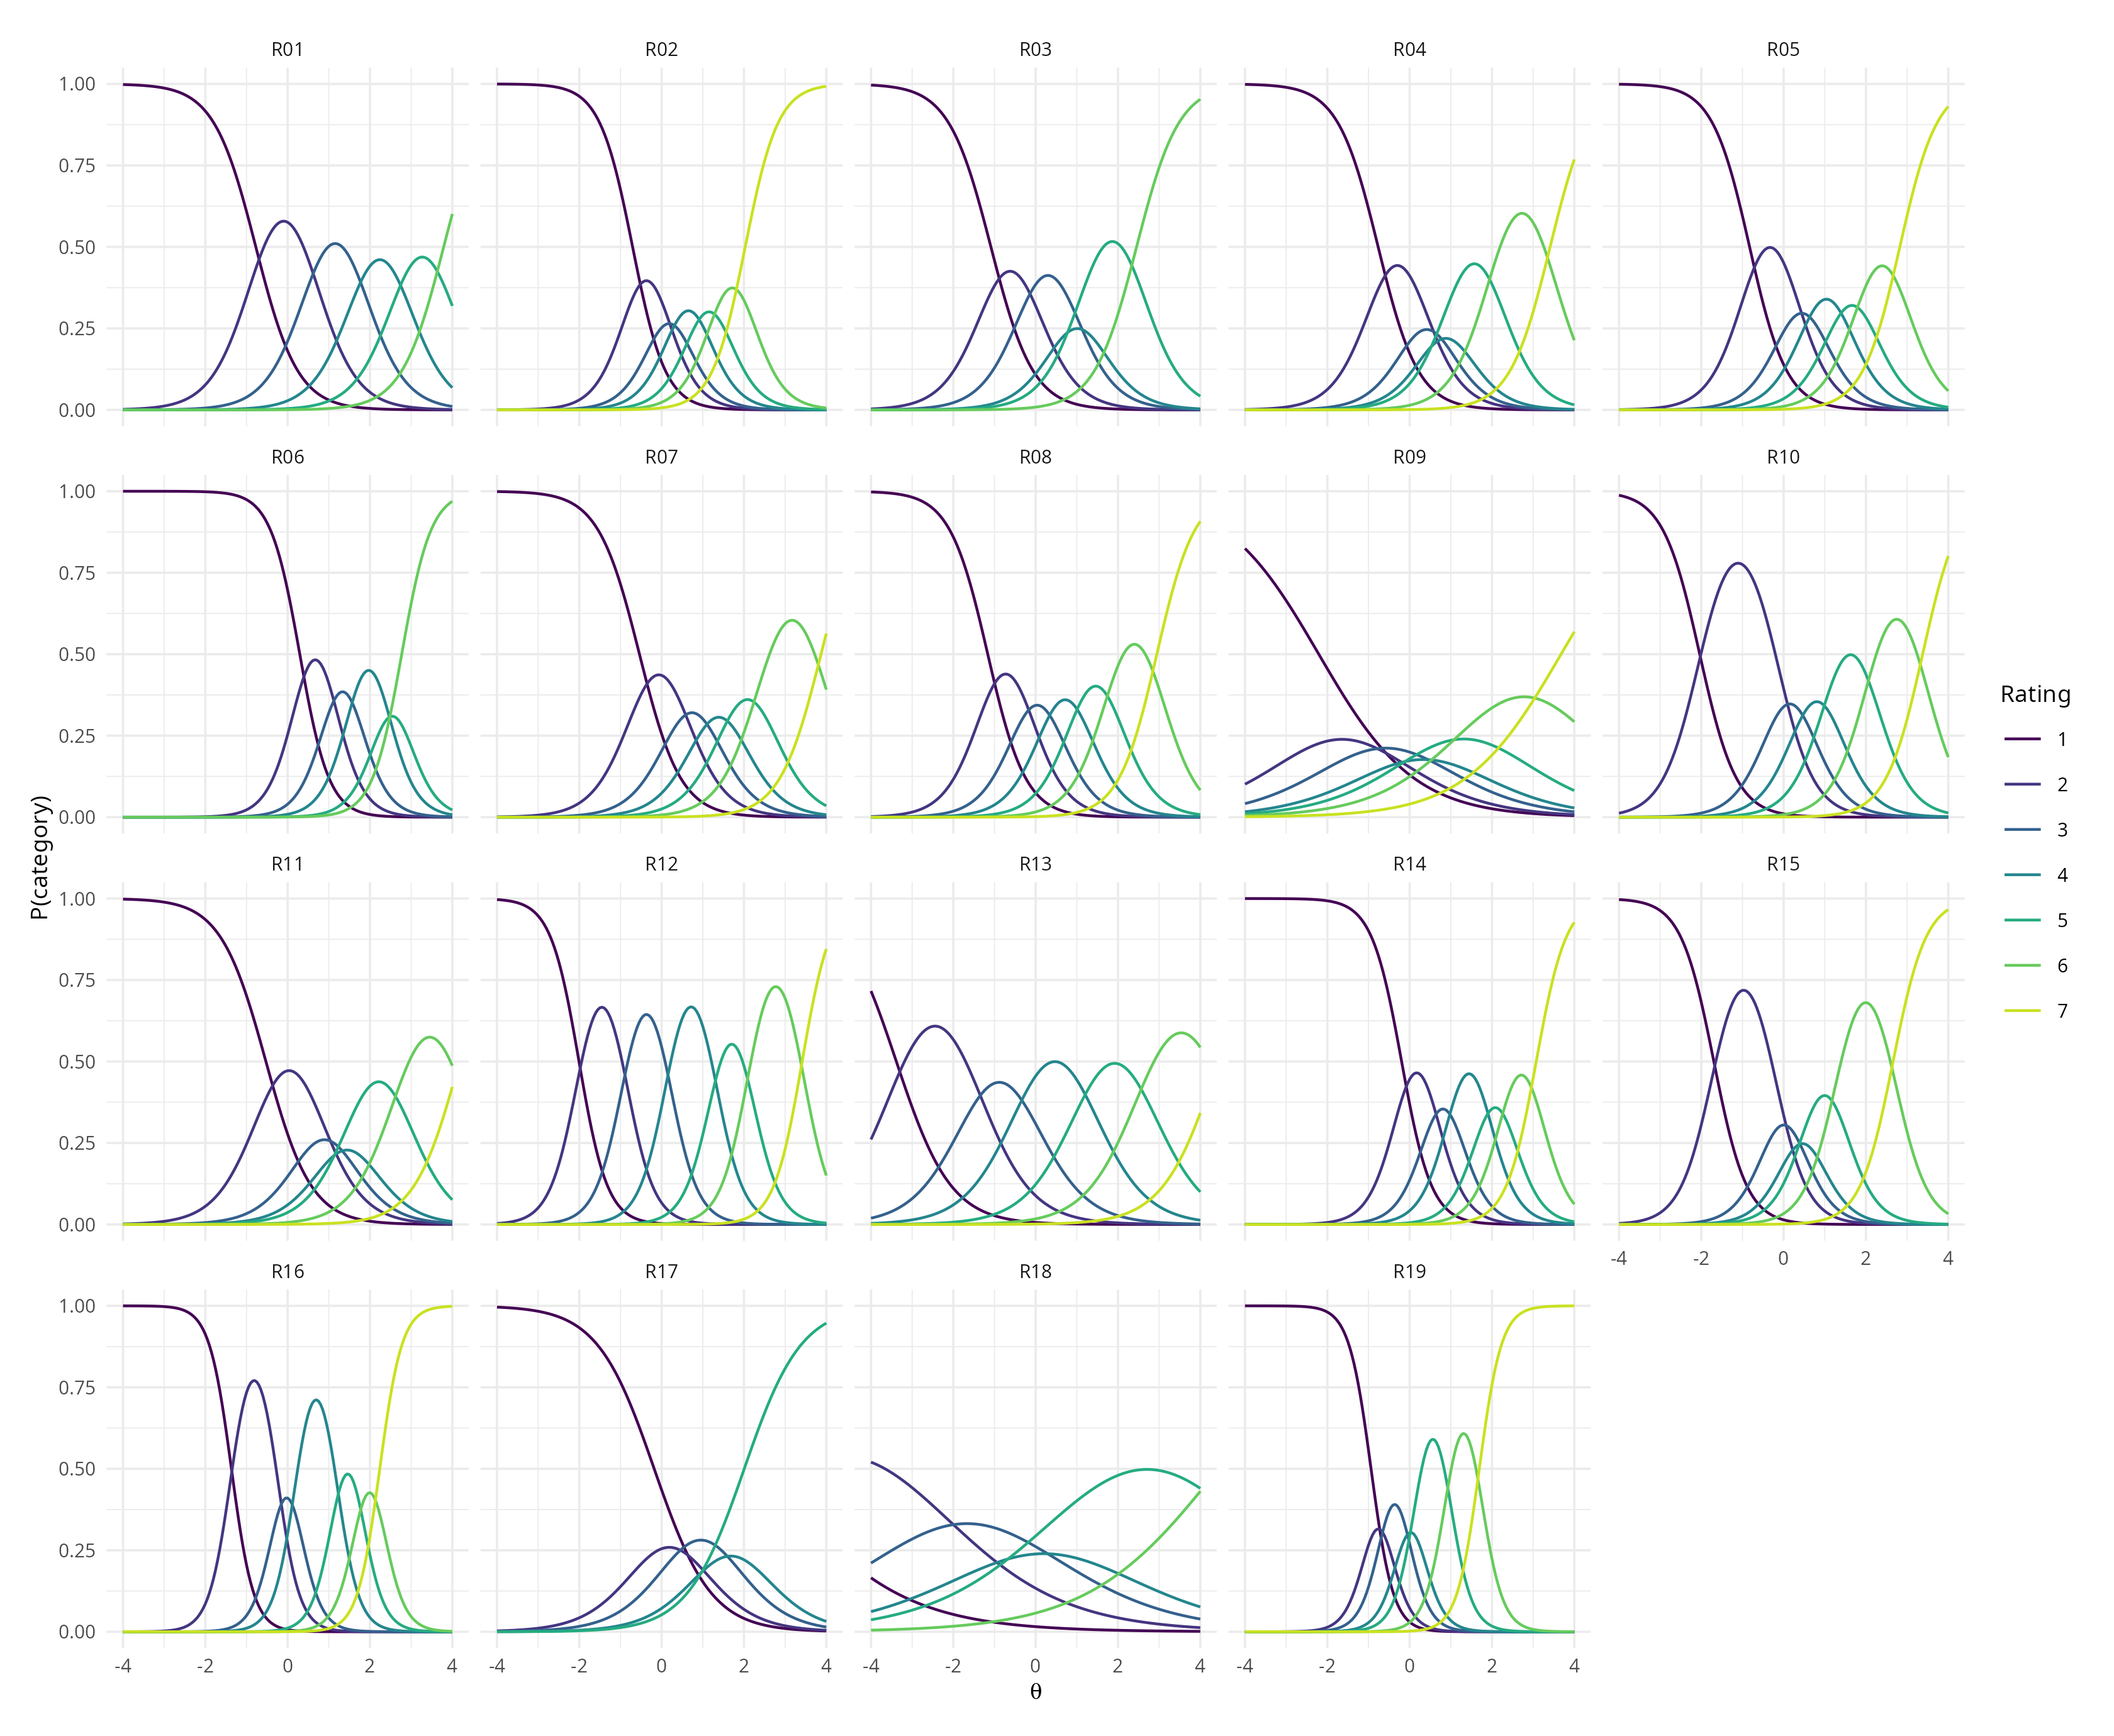

In [7]:
#| label: fig-grm-category-response-functions
#| fig-cap: "Category response functions of the graded response model for each rater."
show_png("grm/figures/grm_category_response_functions.png", width=11)

**Rater fit.** Infit and outfit are mean squares of the standardised residuals, with an expected value of 1 (Wright & Masters, 1982). With about 2 ratings per product, values below 1 are expected, because the score is estimated from the very ratings being checked. S-X² (Orlando & Thissen, 2000; Kang & Chen, 2008) needs complete data, so the missing ratings are imputed 20 times from the fitted model and S-X² is averaged. About 90% of the cells are imputed, which makes the test conservative. No misfit cut-offs for infit and outfit are applied in this notebook.

In [8]:
#| label: tbl-grm-rater-fit
#| tbl-cap: "Rater fit in the graded response model: infit and outfit mean squares (observed ratings) and S-X² pooled over multiple imputations of the missing ratings."
show_table("grm/rater_fit.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit", "S_X2", "df_S_X2", "p_S_X2", "n_imputations"]])

| Rater   | Ratings by rater   | Infit   | Outfit   | S-X²    | df      | p     | Imputations   |
|:--------|:-------------------|:--------|:---------|:--------|:--------|:------|:--------------|
| R01     | 1,174              | 0.680   | 0.650    | 218.569 | 213.550 | 0.392 | 20            |
| R02     | 873                | 0.450   | 0.423    | 289.502 | 300.850 | 0.671 | 20            |
| R03     | 720                | 0.699   | 0.687    | 277.954 | 280.450 | 0.531 | 20            |
| R04     | 620                | 0.588   | 0.554    | 280.793 | 290.200 | 0.643 | 20            |
| R05     | 633                | 0.617   | 0.576    | 291.511 | 293.850 | 0.528 | 20            |
| R06     | 520                | 0.604   | 0.469    | 193.853 | 190.100 | 0.411 | 20            |
| R07     | 547                | 0.724   | 0.645    | 282.598 | 285.850 | 0.543 | 20            |
| R08     | 522                | 0.585   | 0.571    | 282.277 | 285     | 0.534 | 20            |
| R09     | 400                | 0.871   | 0.870    | 440.411 | 433.550 | 0.400 | 20            |
| R10     | 383                | 0.624   | 0.603    | 247.751 | 250.600 | 0.539 | 20            |
| R11     | 369                | 0.829   | 0.784    | 298.249 | 295.100 | 0.438 | 20            |
| R12     | 264                | 0.507   | 0.505    | 207.049 | 196.800 | 0.294 | 20            |
| R13     | 254                | 0.831   | 0.834    | 263.892 | 264.200 | 0.494 | 20            |
| R14     | 259                | 0.483   | 0.398    | 224.935 | 234.450 | 0.661 | 20            |
| R15     | 73                 | 0.754   | 0.663    | 265.749 | 260.900 | 0.405 | 20            |
| R16     | 52                 | 0.508   | 0.480    | 200.549 | 205.150 | 0.578 | 20            |
| R17     | 52                 | 0.926   | 0.824    | 279.802 | 280.350 | 0.498 | 20            |
| R18     | 55                 | 0.971   | 0.961    | 342.054 | 335.700 | 0.394 | 20            |
| R19     | 50                 | 0.334   | 0.322    | 223.516 | 228.400 | 0.579 | 20            |

**Local dependence.** Yen's (1984) Q3 is the correlation between two raters' residuals over the products both rated. It is computed for rater pairs with at least 3 jointly rated products (and residual variance in both raters); other pairs are not computable. With few raters per product, Q3 is biased negatively (Christensen et al., 2017), so the table ranks pairs by their deviation from the mean Q3 over all computable pairs (printed below the table). Flagged marks pairs with at least 30 jointly rated products whose Q3 deviates from the mean Q3 by more than 0.2.

In [9]:
#| label: tbl-grm-q3-flagged
#| tbl-cap: "Rater pairs with the largest local dependence (Q3 minus mean Q3) among pairs with at least 30 jointly rated products."
show_table("grm/q3.csv", lambda d: d[d["n_common"] >= 30].assign(_a=lambda x: x["q3_minus_mean"].abs()).sort_values("_a", ascending=False).drop(columns="_a").head(10))

| Rater 1   | Rater 2   | Shared products   | Q3     | Q3 minus mean Q3   | Overlap   | Flagged   |
|:----------|:----------|:------------------|:-------|:-------------------|:----------|:----------|
| R08       | R19       | 46                | -0.761 | -0.524             | –         | True      |
| R08       | R12       | 51                | -0.743 | -0.506             | –         | True      |
| R02       | R14       | 108               | -0.621 | -0.383             | –         | True      |
| R03       | R10       | 49                | -0.616 | -0.379             | –         | True      |
| R01       | R10       | 157               | -0.613 | -0.376             | –         | True      |
| R02       | R04       | 257               | -0.611 | -0.373             | –         | True      |
| R02       | R08       | 72                | -0.589 | -0.352             | –         | True      |
| R10       | R11       | 32                | 0.105  | 0.343              | –         | True      |
| R01       | R08       | 191               | -0.565 | -0.327             | –         | True      |
| R04       | R14       | 47                | -0.560 | -0.322             | –         | True      |

In [10]:
_q3 = read_res("grm/q3.csv")
if _q3 is not None:
    _ok = _q3["q3"].notna()
    print(f"Mean Q3 over {int(_ok.sum())} computable rater pairs: {(_q3['q3'] - _q3['q3_minus_mean'])[_ok].iloc[0]:.3f}; "
          f"pairs flagged (flag_q3): {int(_q3['flag_q3'].sum())}")

Mean Q3 over 137 computable rater pairs: -0.238; pairs flagged (flag_q3): 20


**Global fit.** C2 is a limited-information test of overall model fit (Cai & Monroe, 2014). The table reports either the statistic or the reason it could not be computed: C2 needs the joint distribution of every pair of raters, which is undefined for rater pairs that share no products.

In [11]:
#| label: tbl-grm-global-fit
#| tbl-cap: "Limited-information absolute fit of the graded response model (C2)."
show_table("grm/global_fit.csv", lambda d: d.drop(columns=["q3_mirt_crosscheck_max_abs_diff"], errors="ignore"))

| Statistic   | Computable   | Rater pairs   | Rater pairs without shared products   | Note                                                                                                            |
|:------------|:-------------|:--------------|:--------------------------------------|:----------------------------------------------------------------------------------------------------------------|
| C2          | False        | 171           | 17                                    | Not computable: 17 of 171 rater pairs share no products, so their bivariate moments and hence C2 are undefined. |

## 3. Information and reliability

**Rater information.** I_j(θ) shows how much a rater's rating tells about θ at each level of creativity. Information from different raters adds up under local independence.

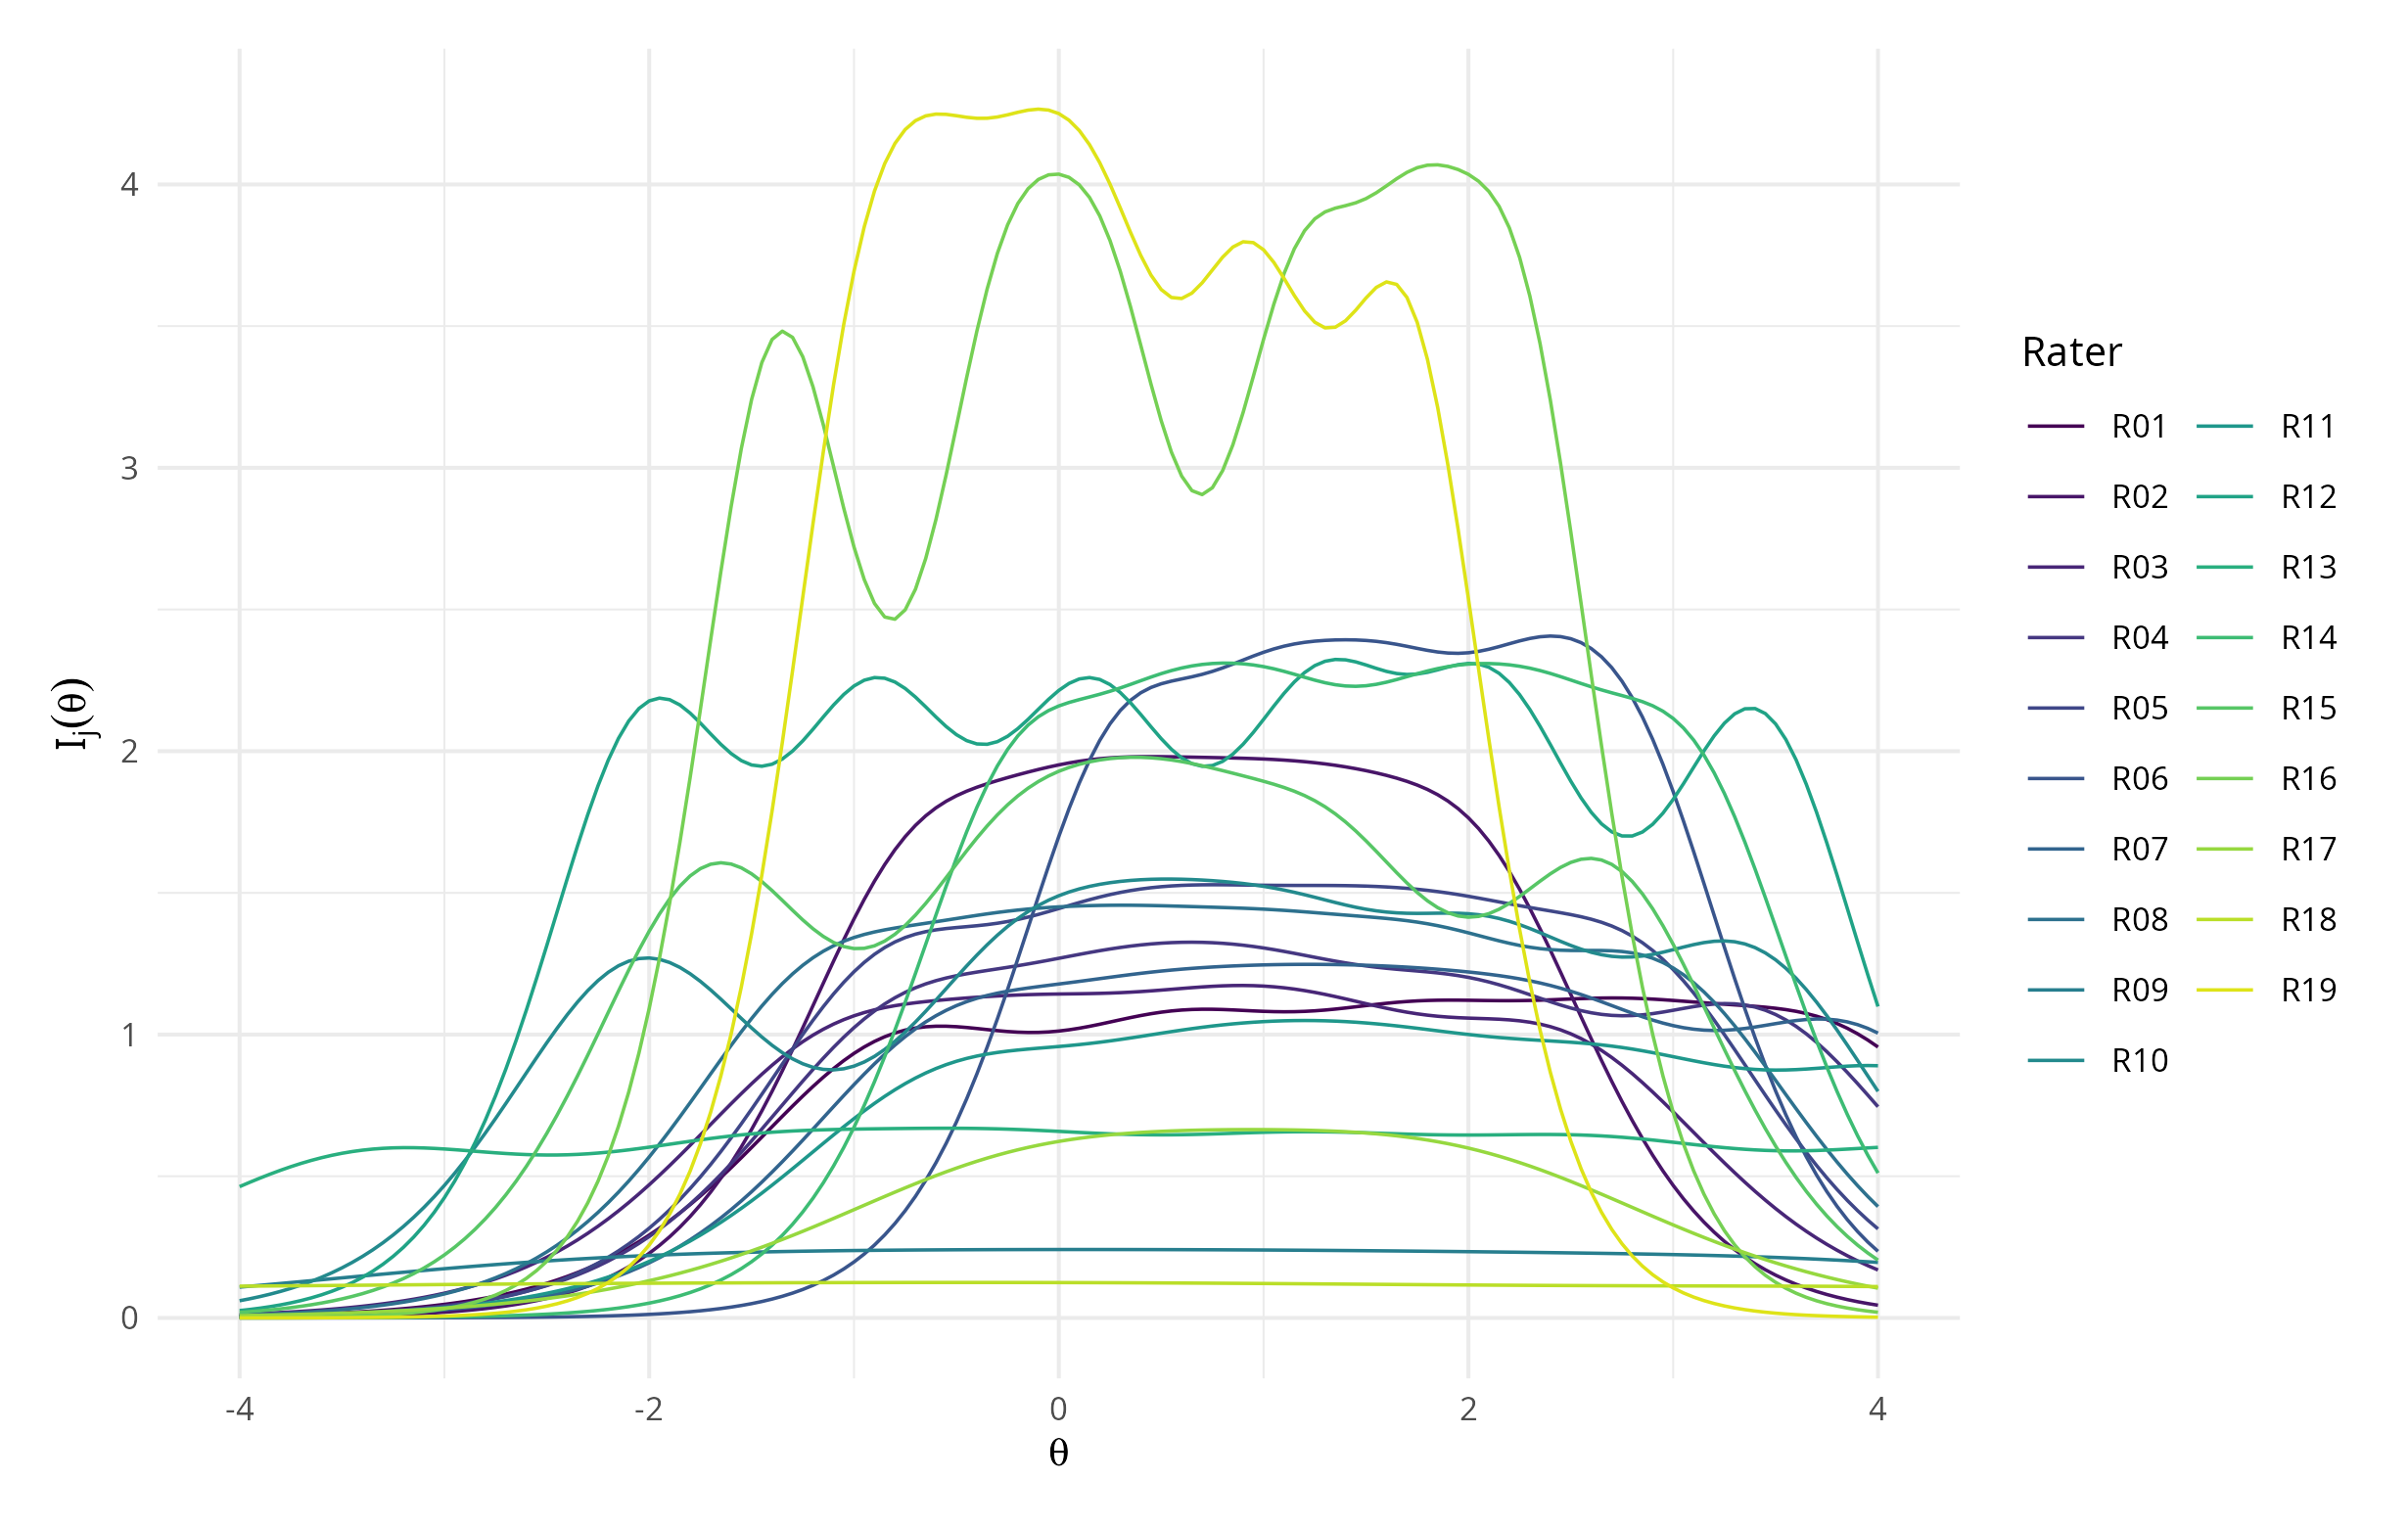

In [12]:
#| label: fig-grm-rater-information
#| fig-cap: "Rater information functions of the graded response model."
show_png("grm/figures/grm_rater_information.png")

**Information shares.** Each rater's share of the total information of all raters, along θ.

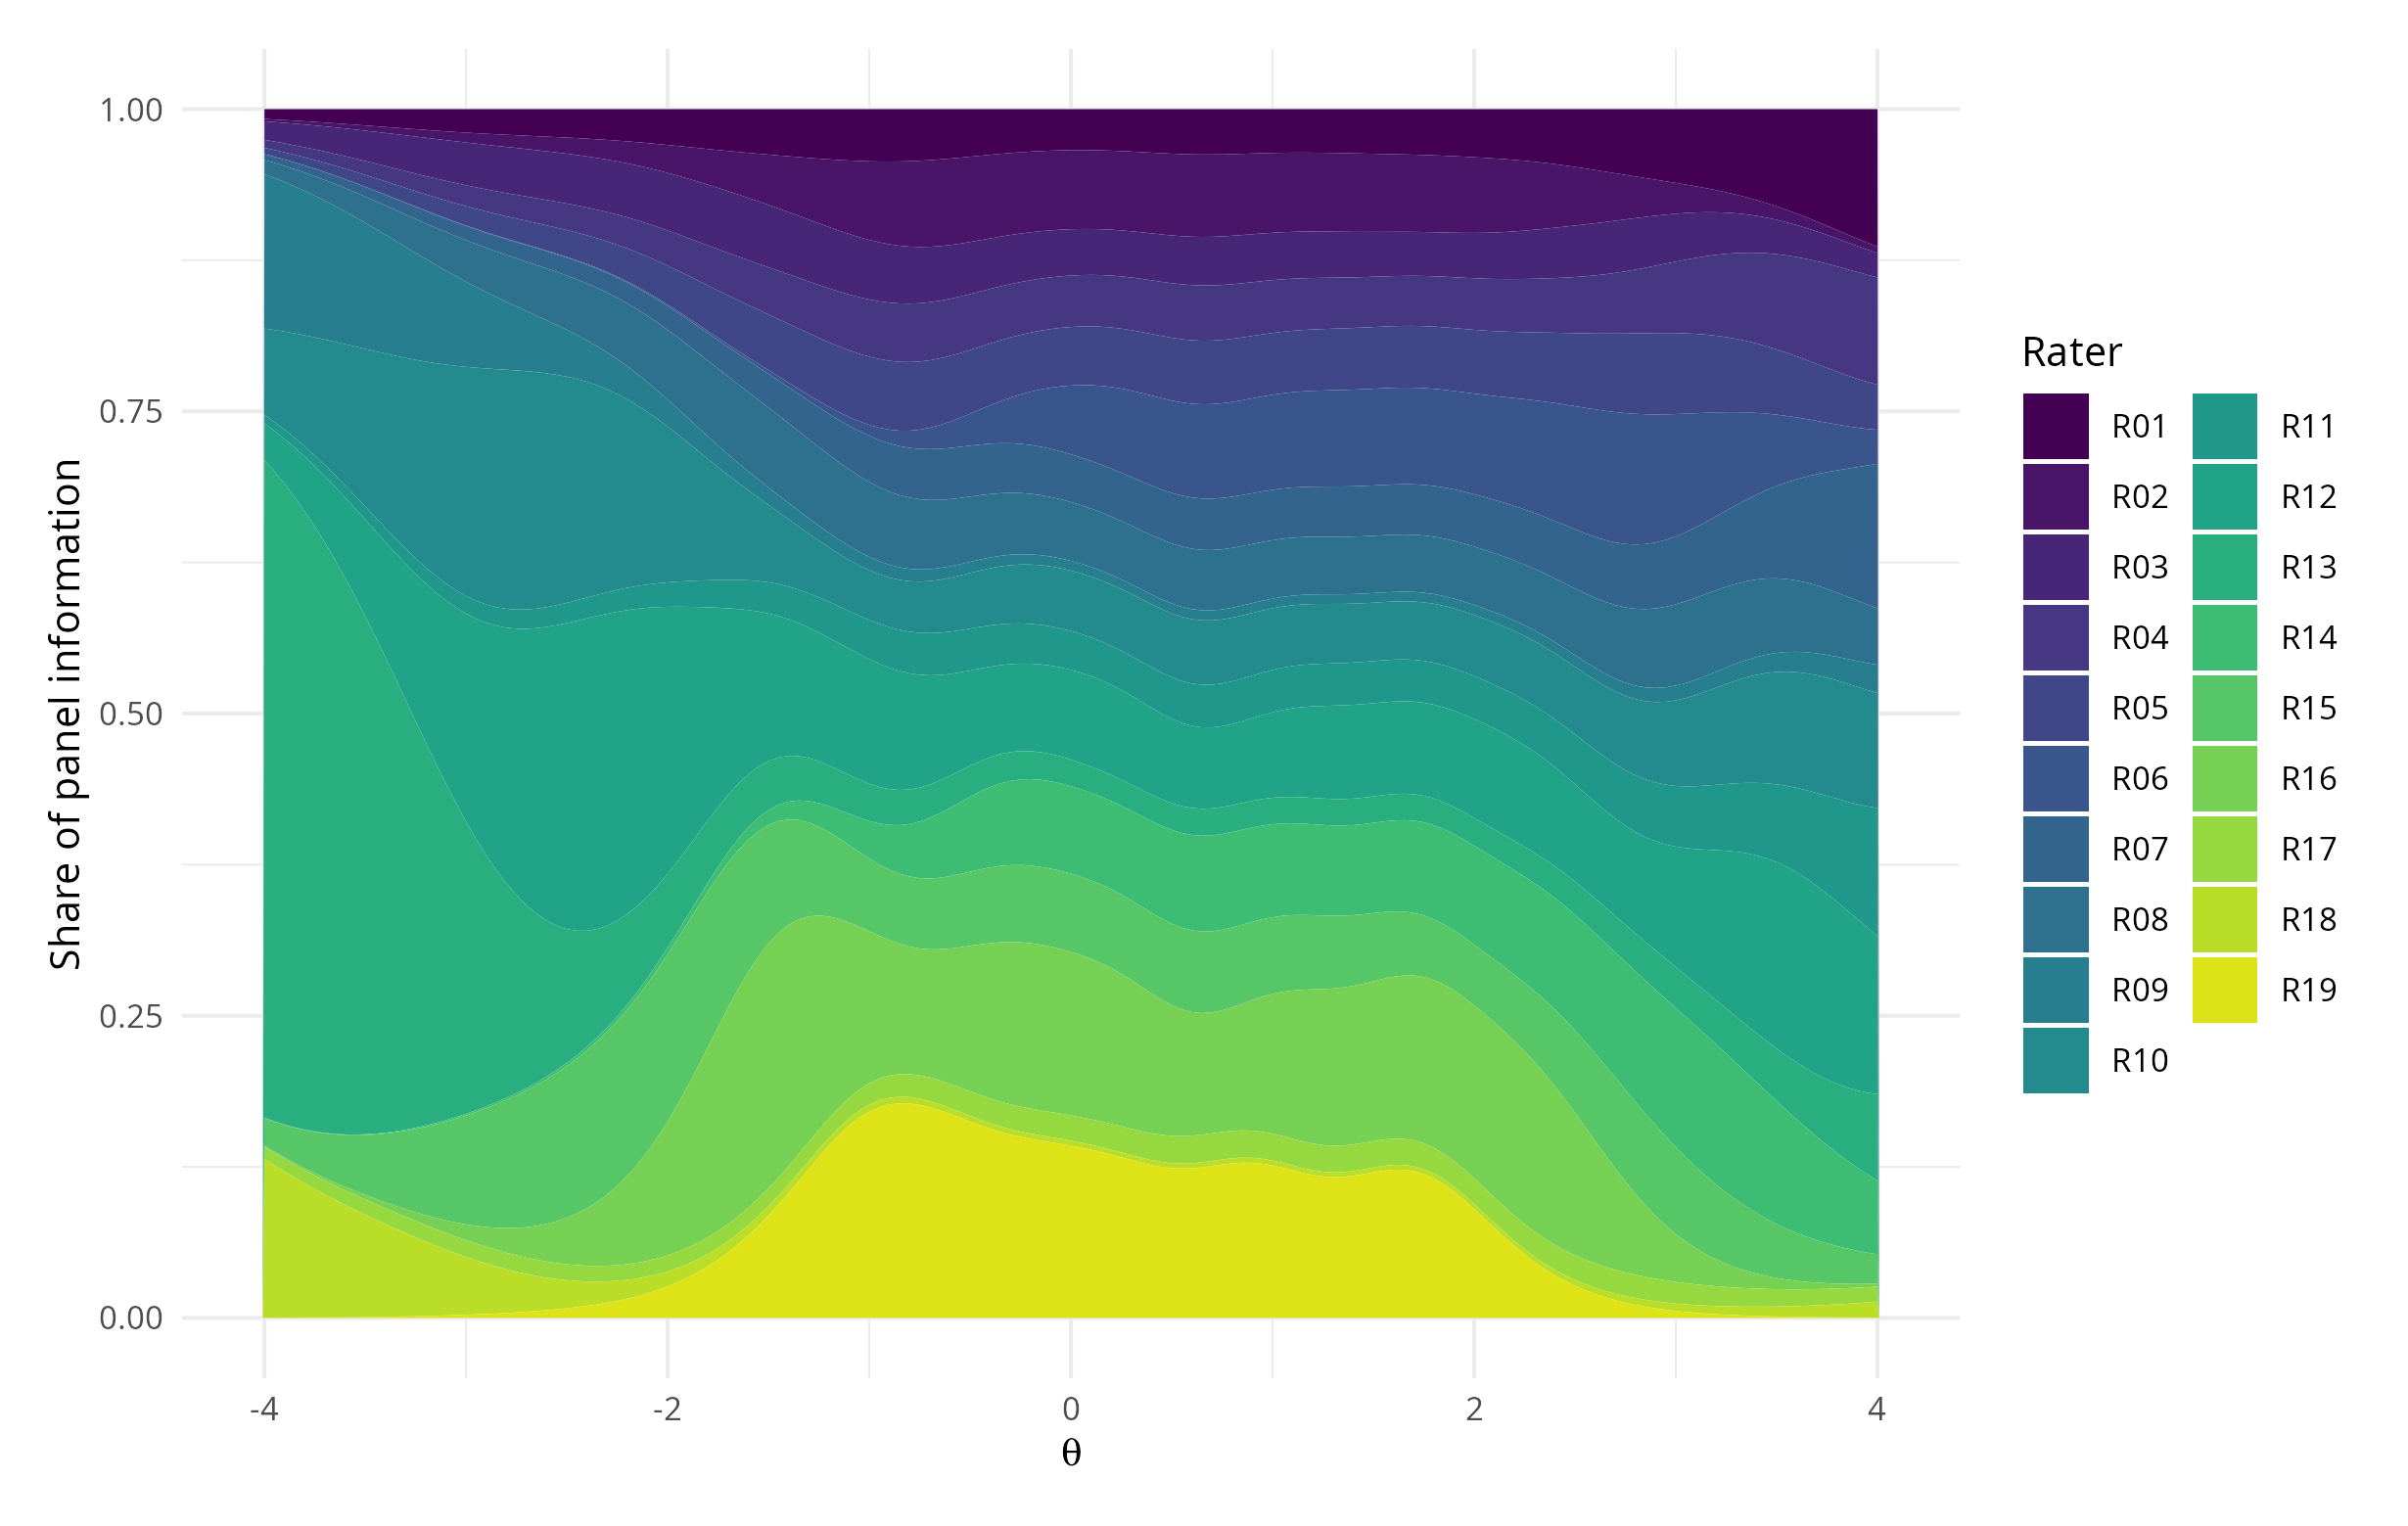

In [13]:
#| label: fig-grm-information-shares
#| fig-cap: "Share of each rater in the information of the full panel across the latent continuum."
show_png("grm/figures/grm_rater_information_shares.png")

**Information summary.** For each rater: information averaged over the N(0, 1) distribution of θ, where it peaks, and the rater's share of the full-panel information.

In [14]:
#| label: tbl-grm-information-summary
#| tbl-cap: "Rater information summary: information integrated over N(0, 1), location and height of the maximum, and share of the full-panel information (weighted over N(0, 1) and at selected values of θ)."
show_table("grm/rater_information_summary.csv")

| Rater   | Ratings by rater   | Information per rating   | θ at maximum   | Maximum information   | Share of panel information   | Share at θ = −2   | Share at θ = −1   | Share at θ = 0   | Share at θ = 1   | Share at θ = 2   |
|:--------|:-------------------|:-------------------------|:---------------|:----------------------|:-----------------------------|:------------------|:------------------|:-----------------|:-----------------|:-----------------|
| R01     | 1,174              | 0.979                    | 2.700          | 1.129                 | 0.037                        | 0.030             | 0.043             | 0.034            | 0.036            | 0.040            |
| R02     | 873                | 1.705                    | 0.450          | 1.981                 | 0.065                        | 0.023             | 0.065             | 0.065            | 0.066            | 0.063            |
| R03     | 720                | 1.080                    | 0.900          | 1.173                 | 0.041                        | 0.048             | 0.049             | 0.038            | 0.039            | 0.038            |
| R04     | 620                | 1.155                    | 0.650          | 1.326                 | 0.044                        | 0.029             | 0.047             | 0.043            | 0.044            | 0.043            |
| R05     | 633                | 1.343                    | 0.750          | 1.529                 | 0.051                        | 0.032             | 0.056             | 0.048            | 0.051            | 0.053            |
| R06     | 520                | 1.410                    | 2.400          | 2.406                 | 0.054                        | 0.001             | 0.009             | 0.057            | 0.079            | 0.083            |
| R07     | 547                | 1.056                    | 1.200          | 1.248                 | 0.040                        | 0.020             | 0.038             | 0.039            | 0.042            | 0.043            |
| R08     | 522                | 1.359                    | 0.300          | 1.456                 | 0.052                        | 0.058             | 0.062             | 0.049            | 0.048            | 0.048            |
| R09     | 400                | 0.238                    | 0.100          | 0.241                 | 0.009                        | 0.022             | 0.011             | 0.008            | 0.008            | 0.008            |
| R10     | 383                | 1.330                    | 0.550          | 1.549                 | 0.051                        | 0.129             | 0.041             | 0.050            | 0.051            | 0.051            |
| R11     | 369                | 0.877                    | 1.200          | 1.050                 | 0.033                        | 0.020             | 0.032             | 0.032            | 0.035            | 0.035            |
| R12     | 264                | 2.120                    | 1.350          | 2.324                 | 0.081                        | 0.221             | 0.103             | 0.074            | 0.071            | 0.082            |
| R13     | 254                | 0.655                    | -0.550         | 0.669                 | 0.025                        | 0.061             | 0.031             | 0.022            | 0.022            | 0.023            |
| R14     | 259                | 1.722                    | 0.800          | 2.311                 | 0.066                        | 0.005             | 0.031             | 0.072            | 0.077            | 0.082            |
| R15     | 73                 | 1.710                    | 0.350          | 1.978                 | 0.065                        | 0.138             | 0.060             | 0.065            | 0.063            | 0.050            |
| R16     | 52                 | 3.300                    | 1.850          | 4.069                 | 0.126                        | 0.111             | 0.126             | 0.135            | 0.116            | 0.143            |
| R17     | 52                 | 0.543                    | 0.950          | 0.665                 | 0.021                        | 0.013             | 0.018             | 0.021            | 0.022            | 0.021            |
| R18     | 55                 | 0.123                    | -0.500         | 0.125                 | 0.005                        | 0.012             | 0.006             | 0.004            | 0.004            | 0.004            |
| R19     | 50                 | 3.539                    | -0.100         | 4.266                 | 0.135                        | 0.026             | 0.171             | 0.142            | 0.126            | 0.090            |

**Full panel.** Information and conditional reliability I/(I+1) if every rater rated a product. This is a hypothetical upper bound, not the precision of the actual scores.

**Uncertainty of rater information.** 95% intervals for each rater's average information and share, from the same parameter draws. Wide intervals mean that a rater's informativeness is not yet well determined, typically for raters with few ratings.

In [15]:
#| label: tbl-grm-rater-information-ci
#| tbl-cap: "Average information per rating (information integrated over θ ~ N(0, 1)) and share of the full-panel information for each rater, with 95% intervals from 200 accepted parameter draws."
show_table("grm/rater_information_ci.csv", lambda d: pd.DataFrame({"rater_id": d["rater_id"], "n_ratings": d["n_ratings"], "Information per rating [95% interval]": est_ci(d, "info_weighted_area", "info_ci_low", "info_ci_high"), "Share of panel information [95% interval]": est_ci(d, "share_weighted", "share_ci_low", "share_ci_high", digits=3)}))

| Rater   | Ratings by rater   | Information per rating [95% interval]   | Share of panel information [95% interval]   |
|:--------|:-------------------|:----------------------------------------|:--------------------------------------------|
| R01     | 1,174              | 0.98 [0.72, 1.22]                       | 0.037 [0.022, 0.050]                        |
| R02     | 873                | 1.70 [0.90, 2.56]                       | 0.065 [0.035, 0.098]                        |
| R03     | 720                | 1.08 [0.75, 1.47]                       | 0.041 [0.023, 0.056]                        |
| R04     | 620                | 1.16 [0.62, 1.74]                       | 0.044 [0.022, 0.064]                        |
| R05     | 633                | 1.34 [0.91, 1.81]                       | 0.051 [0.031, 0.070]                        |
| R06     | 520                | 1.41 [0.88, 2.09]                       | 0.054 [0.033, 0.080]                        |
| R07     | 547                | 1.06 [0.69, 1.38]                       | 0.040 [0.026, 0.057]                        |
| R08     | 522                | 1.36 [0.79, 1.96]                       | 0.052 [0.027, 0.077]                        |
| R09     | 400                | 0.24 [0.11, 0.42]                       | 0.009 [0.004, 0.015]                        |
| R10     | 383                | 1.33 [0.66, 2.03]                       | 0.051 [0.025, 0.081]                        |
| R11     | 369                | 0.88 [0.56, 1.25]                       | 0.033 [0.020, 0.047]                        |
| R12     | 264                | 2.12 [0.94, 3.29]                       | 0.081 [0.036, 0.131]                        |
| R13     | 254                | 0.65 [0.31, 0.98]                       | 0.025 [0.010, 0.037]                        |
| R14     | 259                | 1.72 [0.52, 3.13]                       | 0.066 [0.016, 0.112]                        |
| R15     | 73                 | 1.71 [0.70, 3.08]                       | 0.065 [0.029, 0.112]                        |
| R16     | 52                 | 3.30 [0.73, 6.49]                       | 0.126 [0.026, 0.223]                        |
| R17     | 52                 | 0.54 [0.11, 1.37]                       | 0.021 [0.004, 0.052]                        |
| R18     | 55                 | 0.12 [0.01, 0.35]                       | 0.005 [0.000, 0.013]                        |
| R19     | 50                 | 3.54 [0.41, 11.02]                      | 0.135 [0.017, 0.331]                        |

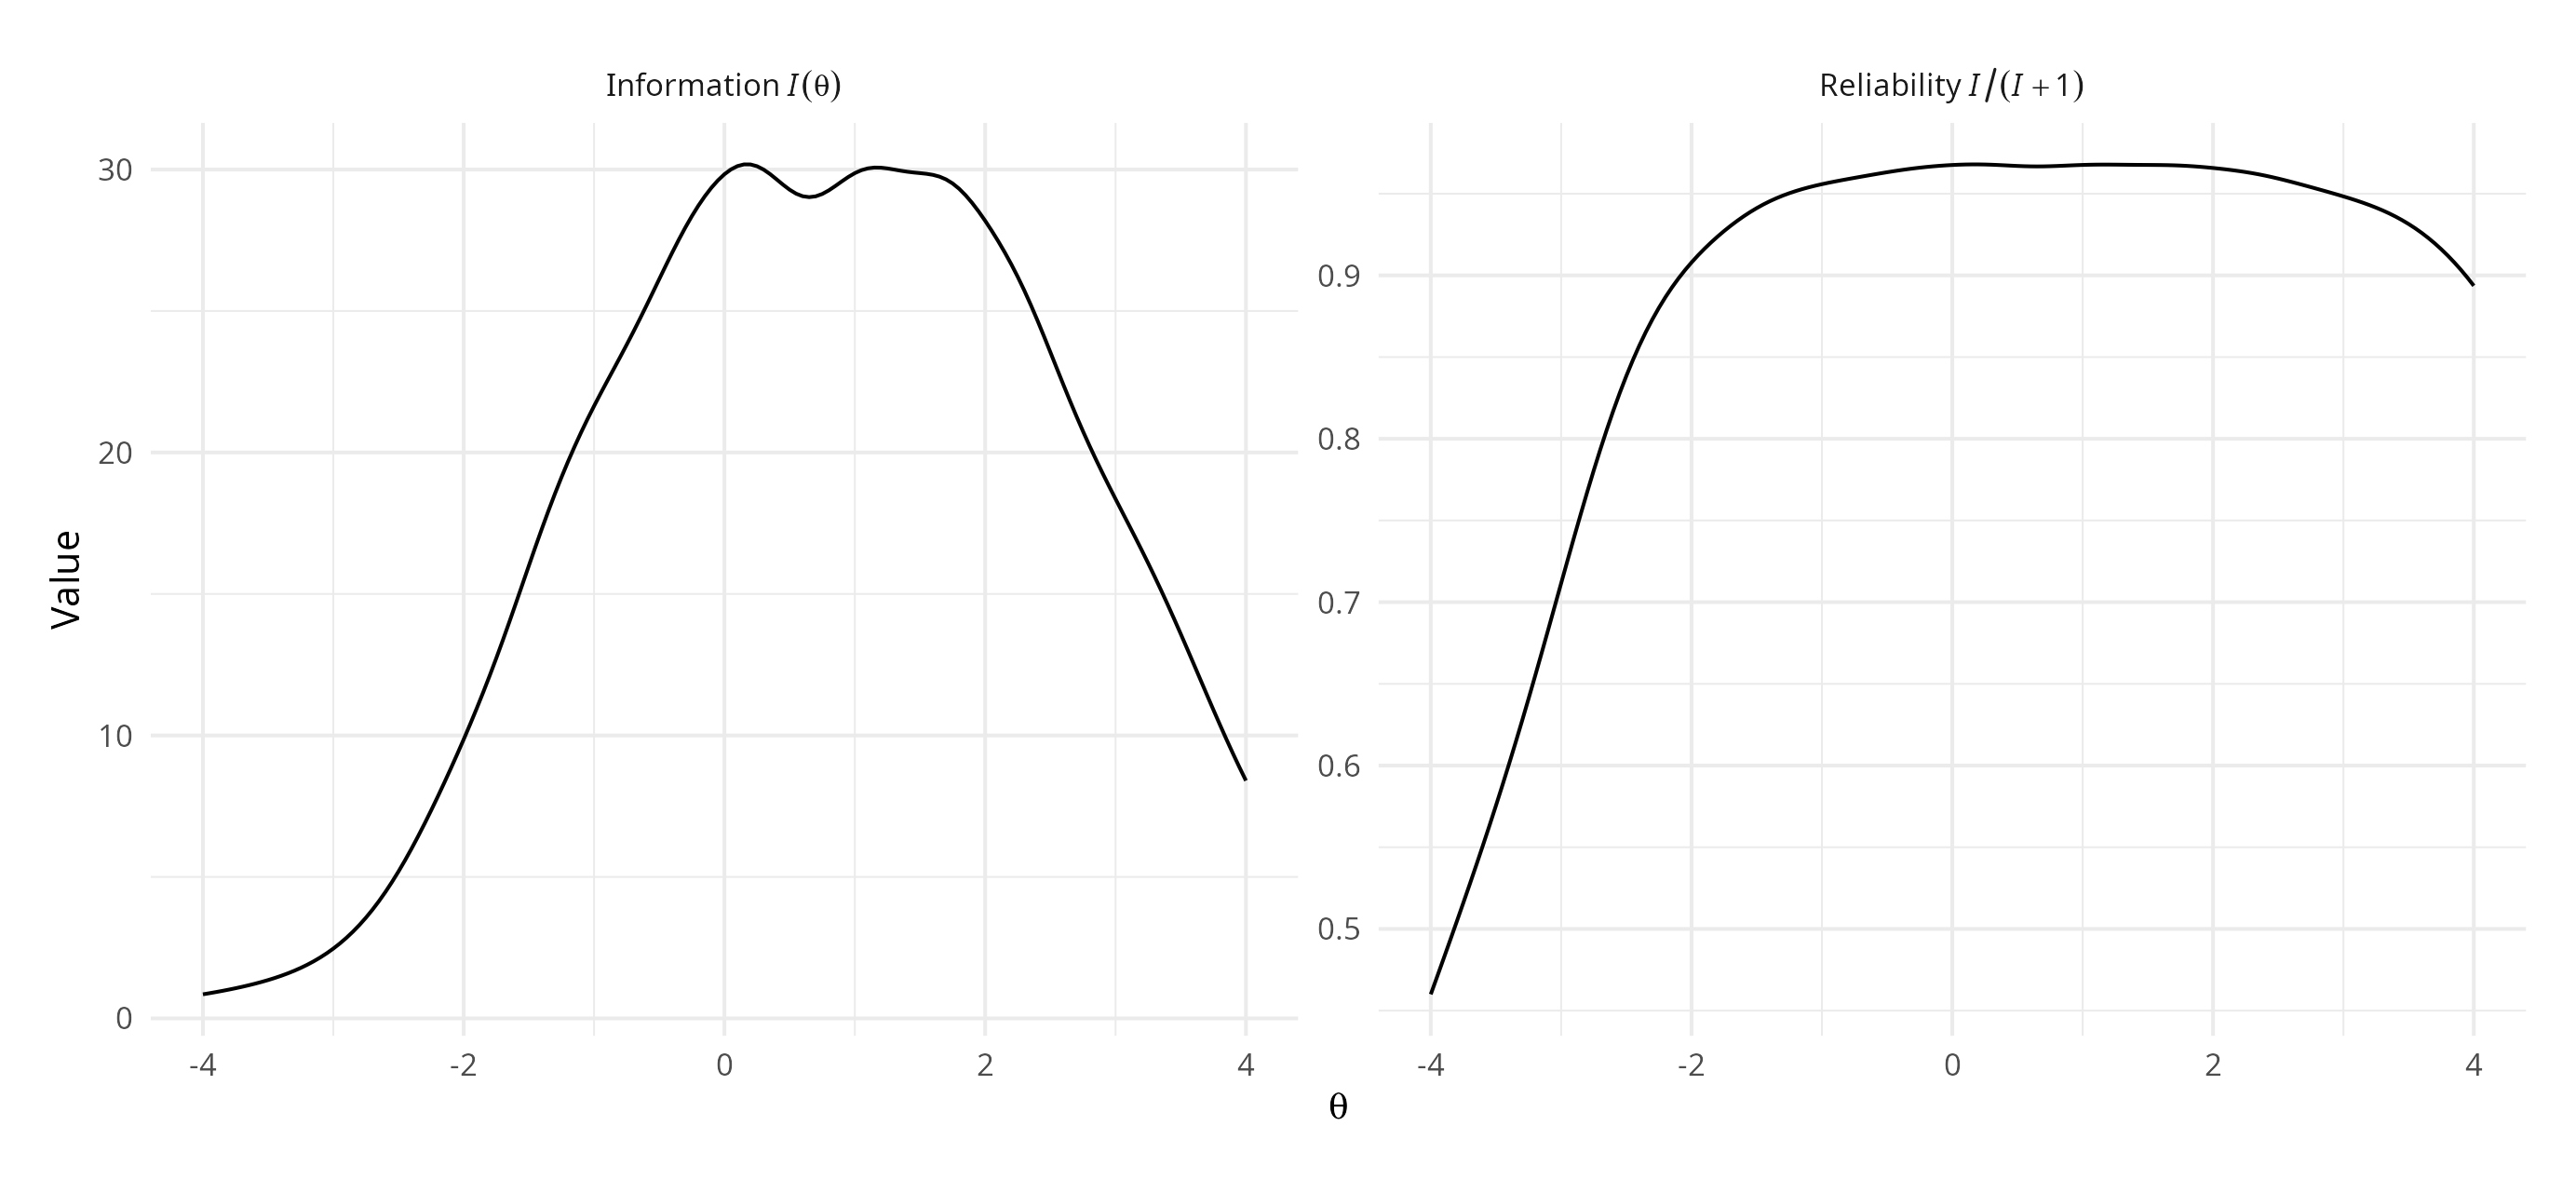

In [16]:
#| label: fig-grm-panel-information
#| fig-cap: "Information and conditional reliability I/(I+1) of the full panel. The curve is hypothetical: it applies to a product rated by all raters."
show_png("grm/figures/grm_panel_information_reliability.png")

**Reliability of the actual scores.** The empirical marginal reliability Var(θ̂)/(Var(θ̂) + mean PSD²) refers to the EAP scores actually obtained (Chalmers, 2012) and is the primary figure. The model-based marginal reliability (Green et al., 1984) refers to the hypothetical full panel. rel_post = 1 − PSD² gives each product's reliability from its own raters.

In [17]:
#| label: tbl-grm-reliability-summary
#| tbl-cap: "Reliability of the GRM scores: empirical marginal reliability of the actual EAP scores (primary), model-based marginal reliability of the hypothetical full panel, distribution of the product-level reliability rel_post = 1 - PSD^2, and its agreement with the information-based rel_info."
show_table("grm/reliability_summary.csv")

| Quantity                                                        | Value   |
|:----------------------------------------------------------------|:--------|
| empirical_marginal_reliability (primary; actual scores)         | 0.672   |
| model_based_marginal_reliability_mirt (hypothetical full panel) | 0.960   |
| model_based_marginal_reliability_grid (check)                   | 0.960   |
| var theta eap                                                   | 0.672   |
| mean psd squared                                                | 0.328   |
| rel post min                                                    | 0.057   |
| rel post p10                                                    | 0.485   |
| rel post q1                                                     | 0.596   |
| rel post median                                                 | 0.698   |
| rel post q3                                                     | 0.769   |
| rel post p90                                                    | 0.813   |
| rel post max                                                    | 0.929   |
| rel post mean                                                   | 0.672   |
| rel post iqr                                                    | 0.173   |
| consistency cor rel post rel info                               | 0.935   |
| consistency mean diff rel info minus rel post                   | 0.016   |
| consistency max abs diff                                        | 0.413   |
| products abs diff gt 0.1                                        | 320     |

**Reliability by number of ratings.** How product-level precision grows with the number of ratings a product received.

**Uncertainty of the marginal reliabilities.** 95% intervals from 200 draws of the model parameters from their asymptotic normal distribution (estimates and Oakes covariance matrix). For the empirical reliability, products are also resampled in each draw. Draws counts the accepted draws. A draw is rejected and replaced when it is not a valid GRM, that is when some discrimination a ≤ 0 or some rater's thresholds are out of order; Draws rejected counts these.

In [18]:
#| label: tbl-grm-reliability-ci
#| tbl-cap: "Empirical and model-based marginal reliability of the GRM with 95% intervals from accepted parameter draws; draws that did not give a valid GRM were rejected and replaced."
show_table("grm/reliability_ci.csv", lambda d: d[["quantity", "estimate", "ci_low", "ci_high", "n_draws", "n_draws_rejected"]])

| Quantity                         | Estimate   | 95% CI lower   | 95% CI upper   | Draws   | Draws rejected   |
|:---------------------------------|:-----------|:---------------|:---------------|:--------|:-----------------|
| empirical marginal reliability   | 0.672      | 0.649          | 0.687          | 200     | 87               |
| model based marginal reliability | 0.960      | 0.953          | 0.968          | 200     | 87               |

In [19]:
#| label: tbl-grm-reliability-by-n
#| tbl-cap: "Product-level reliability and posterior SD by number of ratings per product."
show_table("grm/reliability_by_n_ratings.csv", lambda d: d.rename(columns={"n_ratings": "ratings_per_product"}))

| Ratings per product   | Products   | Mean rel_post   | Median rel_post   | Mean rel_info   | Mean PSD   |
|:----------------------|:-----------|:----------------|:------------------|:----------------|:-----------|
| 1                     | 897        | 0.520           | 0.553             | 0.544           | 0.686      |
| 2                     | 2,080      | 0.698           | 0.714             | 0.713           | 0.545      |
| 3                     | 357        | 0.757           | 0.768             | 0.767           | 0.488      |
| 4                     | 125        | 0.810           | 0.826             | 0.818           | 0.430      |
| 5                     | 125        | 0.820           | 0.831             | 0.831           | 0.420      |
| 6                     | 47         | 0.847           | 0.856             | 0.851           | 0.387      |
| 7                     | 20         | 0.869           | 0.880             | 0.874           | 0.358      |
| 8                     | 11         | 0.875           | 0.885             | 0.879           | 0.347      |
| 9                     | 3          | 0.879           | 0.920             | 0.883           | 0.338      |
| 10                    | 3          | 0.919           | 0.920             | 0.917           | 0.285      |

Distribution of product-level reliability across products.

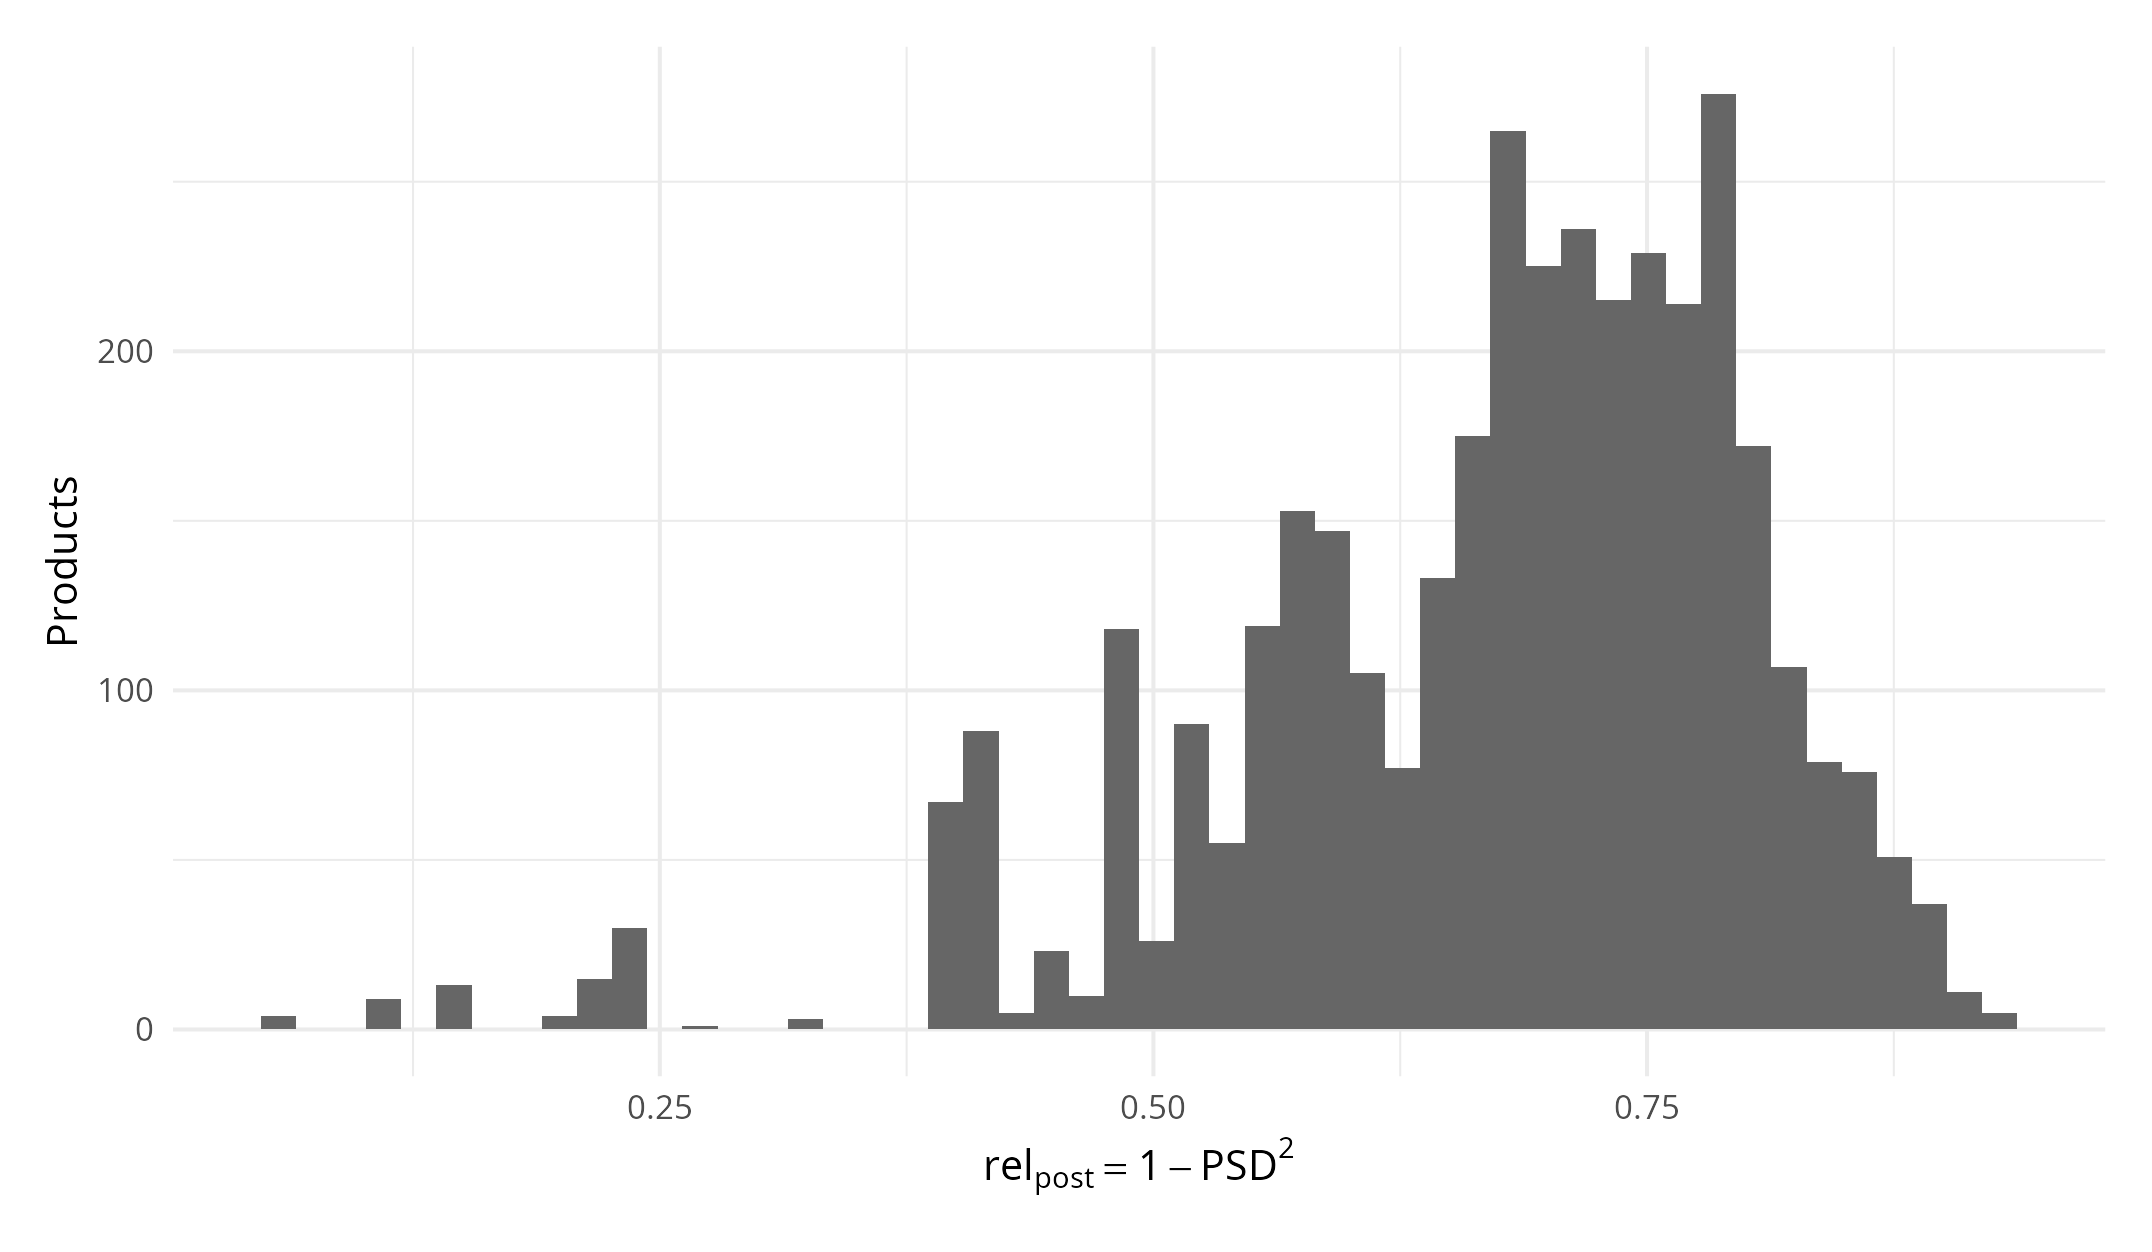

In [20]:
#| label: fig-grm-rel-post-histogram
#| fig-cap: "Distribution of the product-level reliability (1 − PSD²) across all products."
show_png("grm/figures/grm_rel_post_histogram.png")

Product-level reliability by number of ratings (the same information as the table above, as a figure).

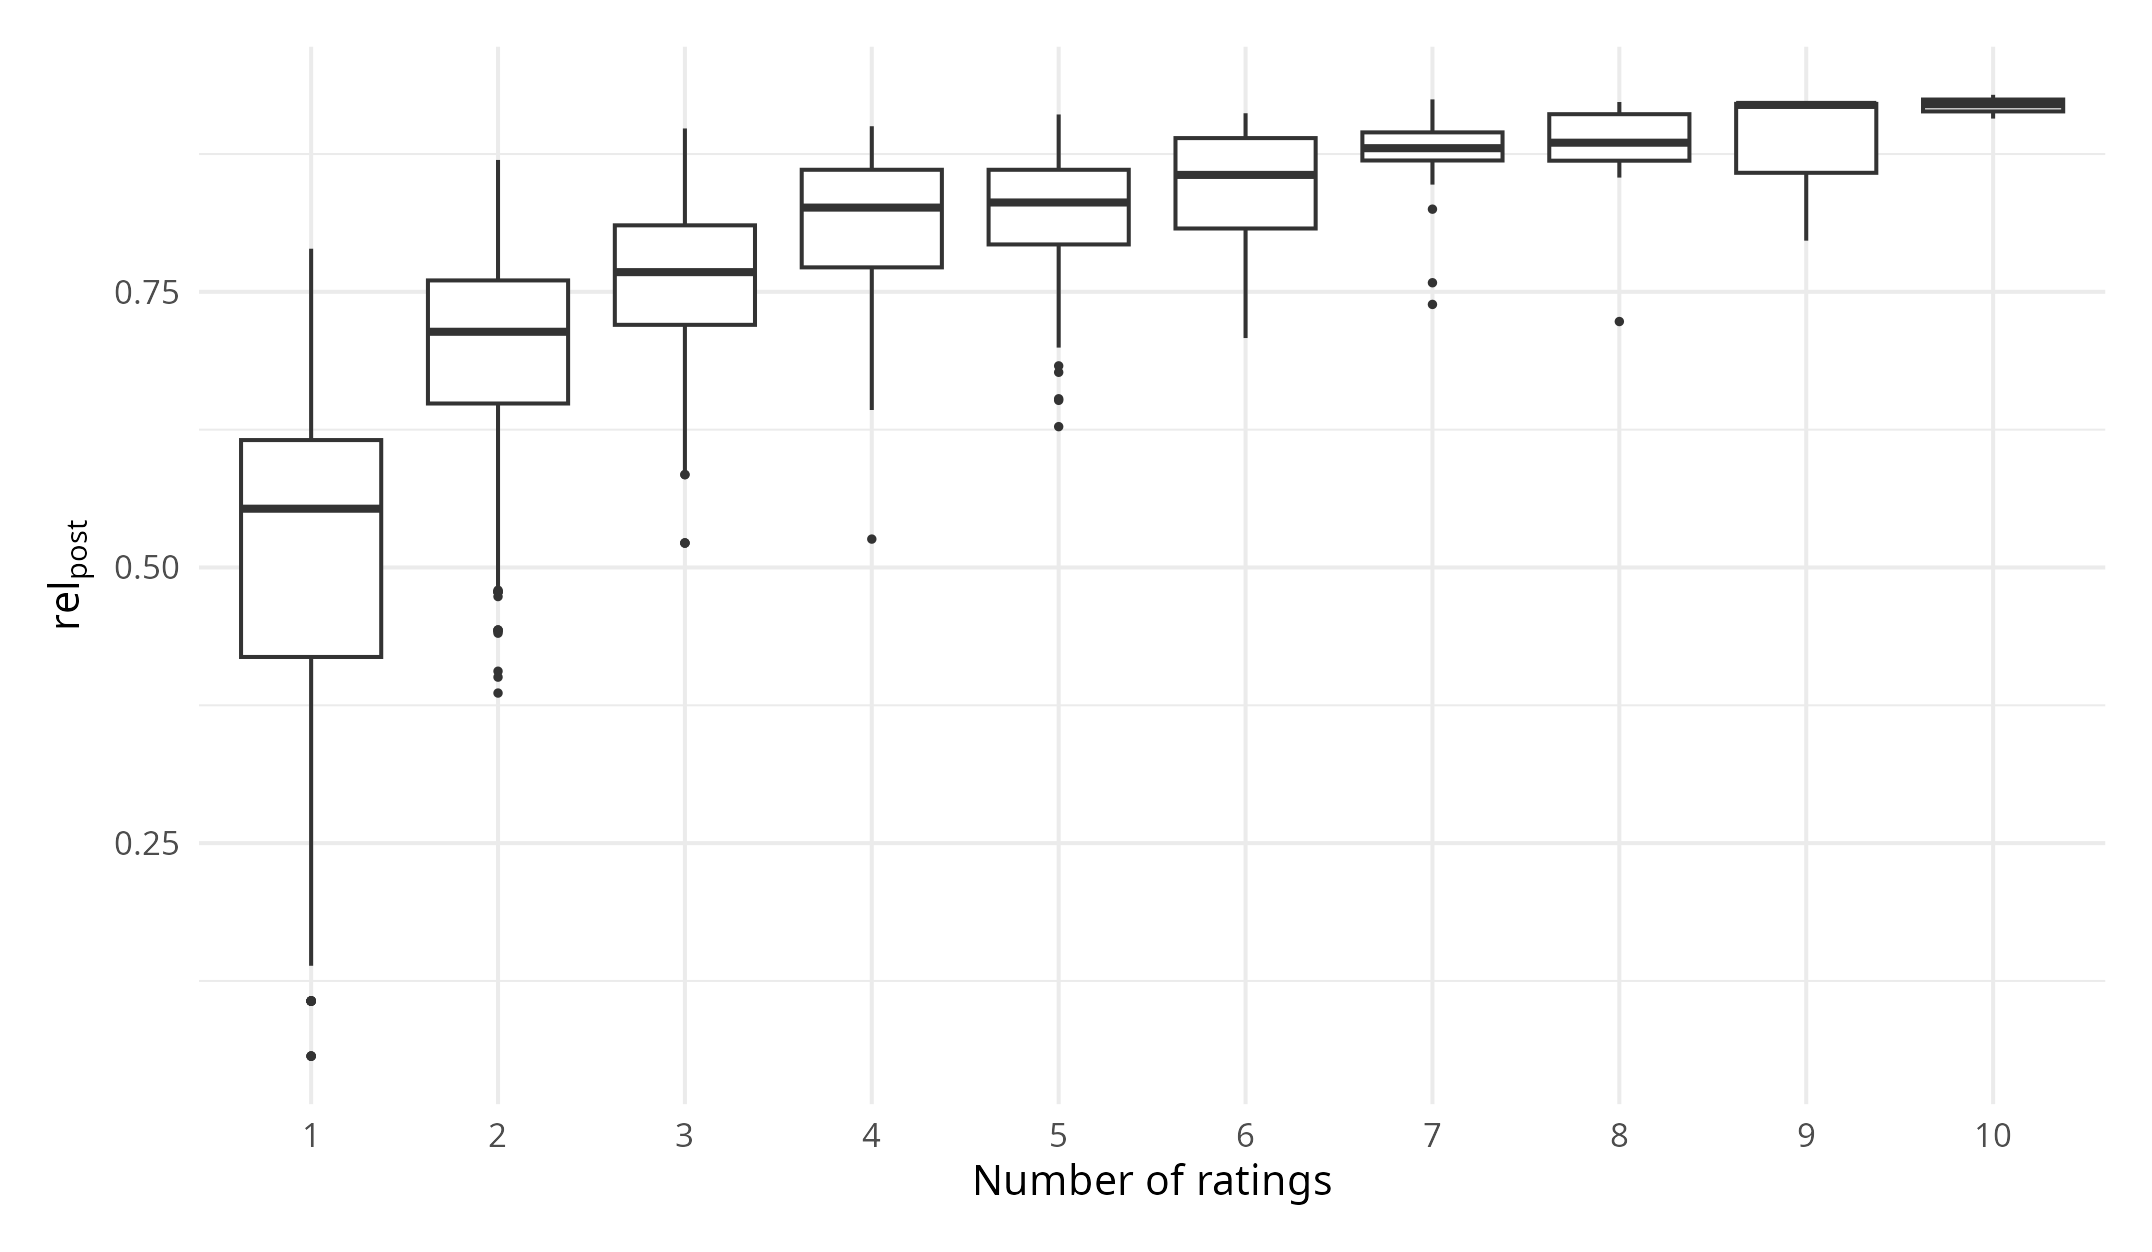

In [21]:
#| label: fig-grm-rel-post-by-n
#| fig-cap: "Product-level reliability (1 − PSD²) by number of ratings per product."
show_png("grm/figures/grm_rel_post_by_n_ratings.png")

**Side note: projected reliability with more ratings.** A simple gauge of the value of adding ratings, supplementary to the observed values above. Products with θ ~ N(0, 1) are simulated; each gets k ratings from k raters of the actual panel, drawn at random, with ratings generated from the fitted GRM and scored with its parameters (treated as known). The table gives the empirical marginal reliability (mean and 95% range over replications) and the mean product-level reliability rel_post.

In [22]:
#| label: tbl-grm-reliability-projection
#| tbl-cap: "Projected reliability of GRM scores by number of ratings per product (k), simulated from the fitted model with raters of the panel drawn at random (each equally likely): empirical marginal reliability with its 95% range over 50 replications of 2,000 products, and mean product-level reliability (1 − PSD²)."
show_table("grm/reliability_projection.csv", lambda d: pd.DataFrame({"k": d["k"], "empirical": est_ci(d, "empirical", "empirical_q025", "empirical_q975", digits=3), "mean_rel_post": d["mean_rel_post"]}))

| Ratings per product (k)   | Empirical reliability [95% range]   | Mean rel_post   |
|:--------------------------|:------------------------------------|:----------------|
| 1                         | 0.508 [0.495, 0.522]                | 0.508           |
| 2                         | 0.688 [0.676, 0.698]                | 0.690           |
| 3                         | 0.775 [0.764, 0.784]                | 0.776           |
| 4                         | 0.826 [0.817, 0.832]                | 0.826           |
| 5                         | 0.857 [0.850, 0.864]                | 0.857           |
| 6                         | 0.880 [0.872, 0.884]                | 0.879           |
| 7                         | 0.896 [0.891, 0.901]                | 0.896           |
| 8                         | 0.908 [0.903, 0.911]                | 0.908           |
| 9                         | 0.918 [0.914, 0.921]                | 0.918           |
| 10                        | 0.925 [0.922, 0.929]                | 0.926           |

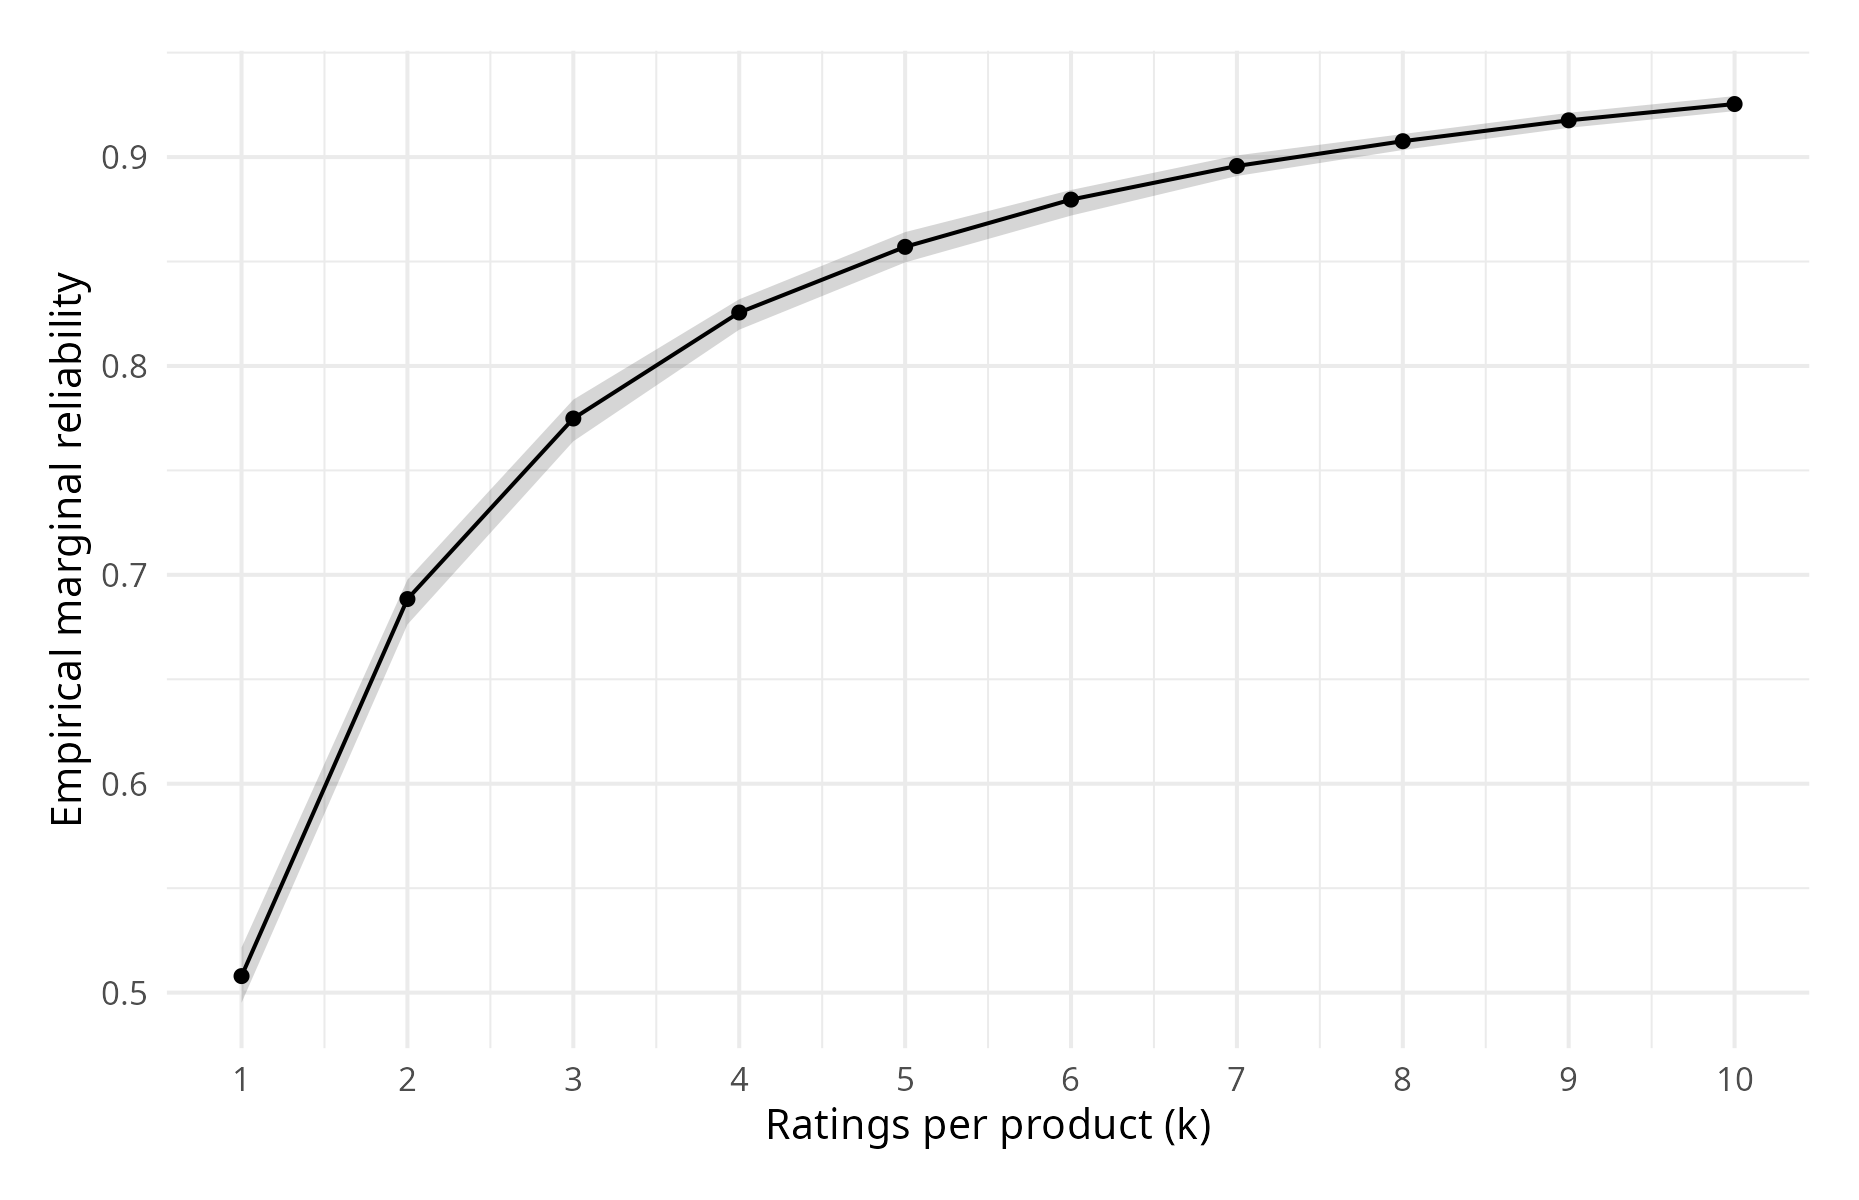

In [23]:
#| label: fig-grm-reliability-projection
#| fig-cap: "Projected empirical marginal reliability by number of ratings per product, simulated from the fitted GRM with randomly drawn raters. Band: 95% range over replications."
show_png("grm/figures/grm_reliability_projection.png", width=6)

In [24]:
_pr = read_res("grm/reliability_projection.csv")
if _pr is not None:
    print(f"{int(_pr['n_reps'].iloc[0])} replications of {int(_pr['n_products_per_rep'].iloc[0])} simulated products per k; seed {int(_pr['seed'].iloc[0])}.")

50 replications of 2000 simulated products per k; seed 20260713.


Product-level reliability by estimated creativity. Precision depends on where a product lies relative to its raters' thresholds.

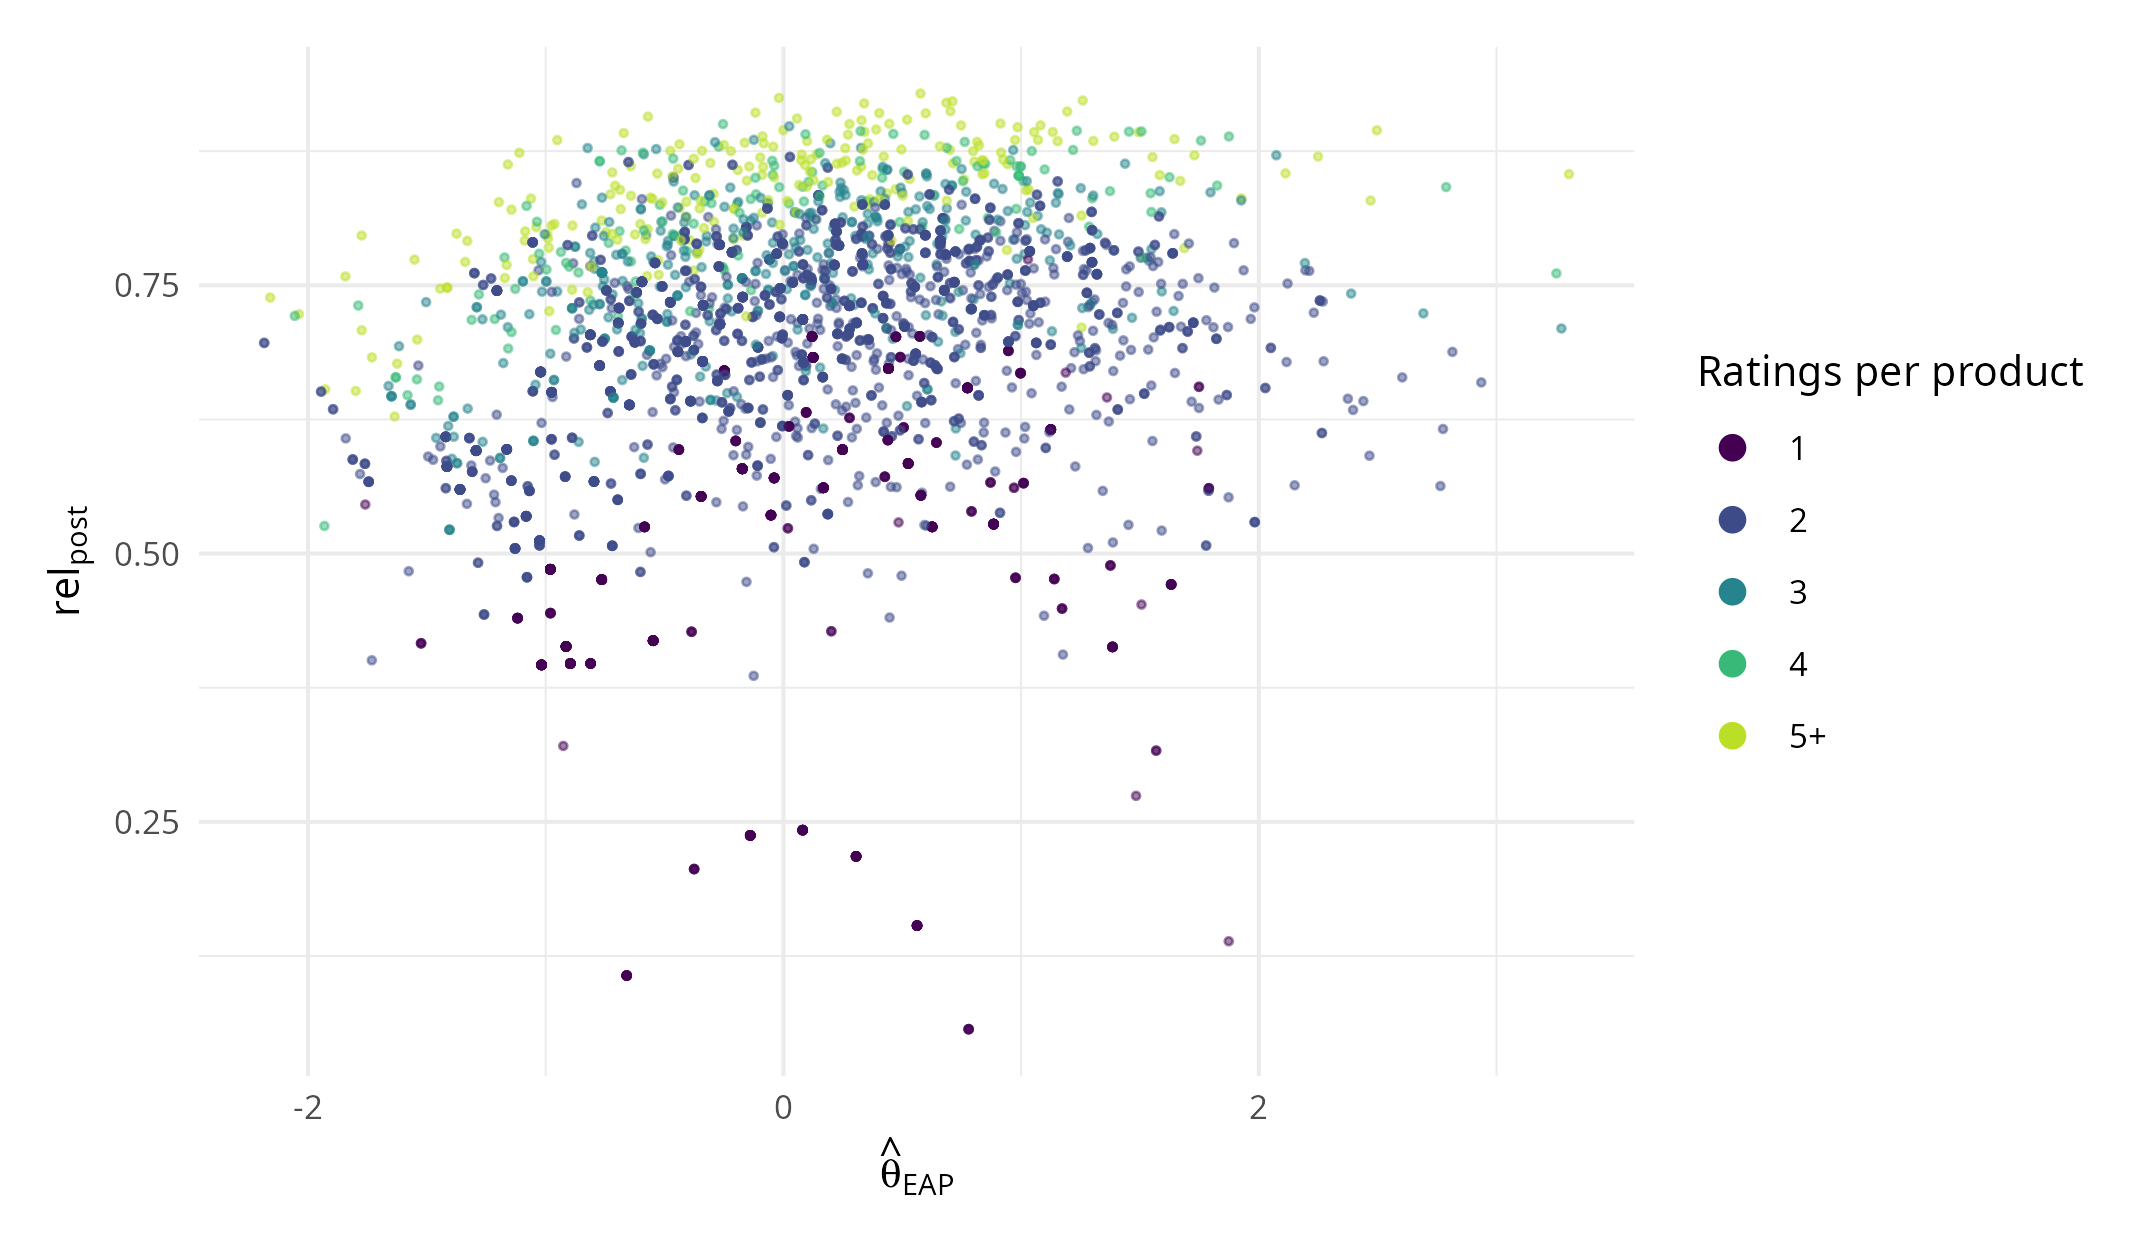

In [25]:
#| label: fig-grm-rel-post-by-theta
#| fig-cap: "Product-level reliability (1 − PSD²) by EAP estimate, coloured by number of ratings per product."
show_png("grm/figures/grm_rel_post_by_theta.png")

**Check.** Two routes to the same product-level reliability: from the posterior (rel_post) and from the information of the product's own raters (rel_info). Points near the diagonal mean the two routes agree.

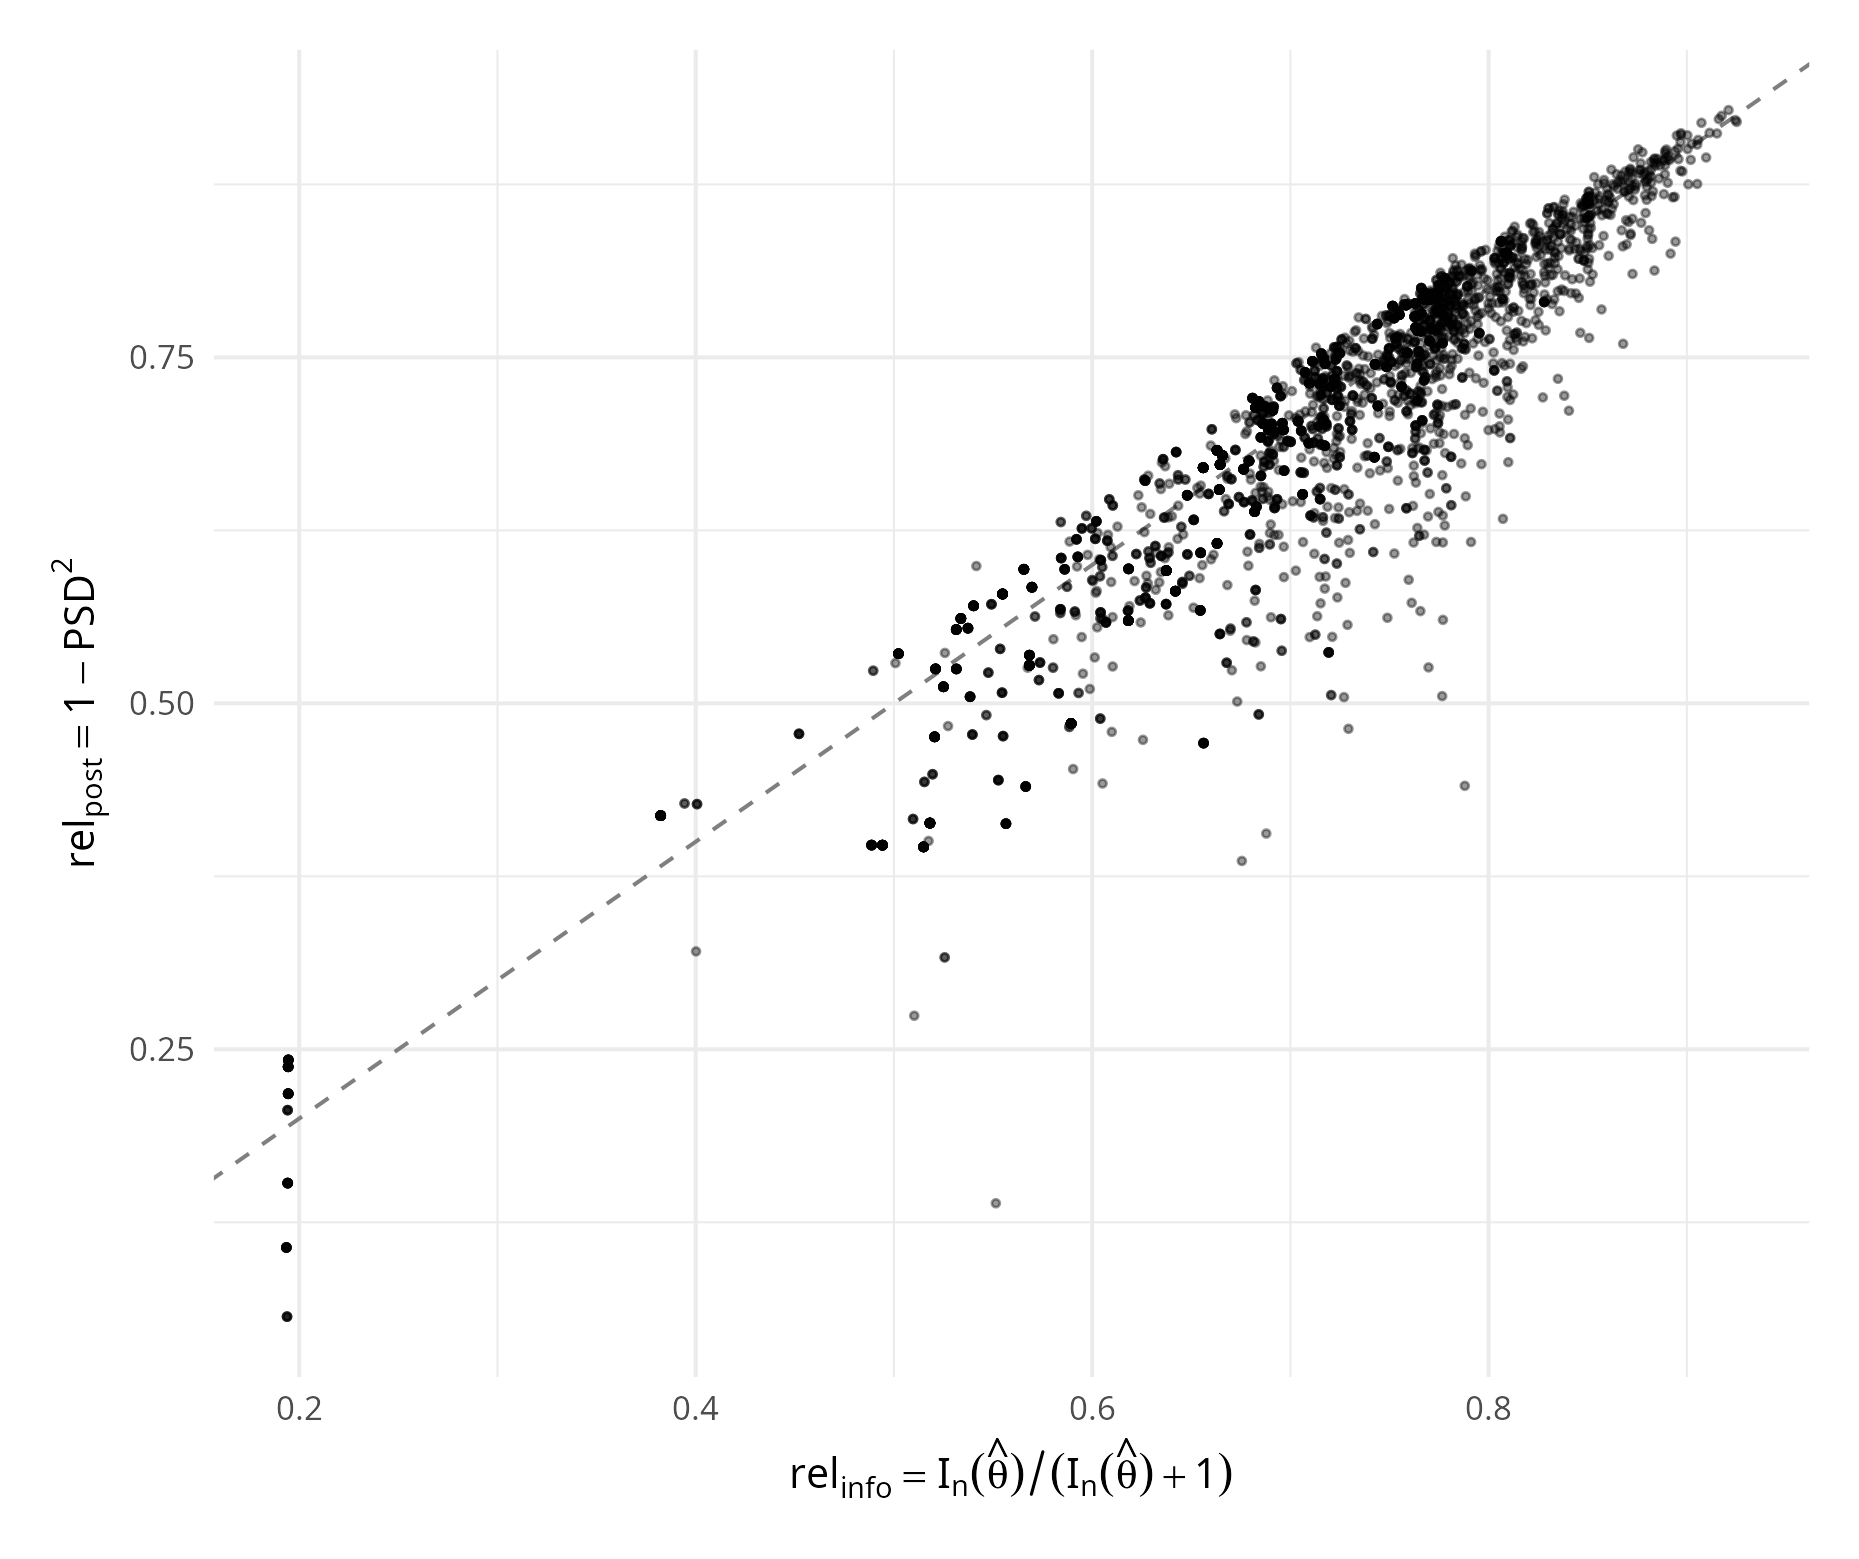

In [26]:
#| label: fig-grm-rel-consistency
#| fig-cap: "Agreement of the two product-level reliability indices: rel_info (information of the product's own raters at the EAP estimate) and rel_post (1 − PSD²)."
show_png("grm/figures/grm_rel_consistency.png", width=6)

## 4. Comparison: model ladder and MFRM

**Model comparison.** The adjacent-category models form a ladder:
- M1, the rating scale model with a rater shift (Andrich, 1978). This is the many-facet Rasch model (Linacre, 1989; Primi et al., 2019), fitted with `sirt::rm.facets`.
- M2, the partial credit model (Masters, 1982): adds rater-specific thresholds.
- M3, the generalized partial credit model (Muraki, 1992): adds rater-specific discriminations.

The GRM belongs to the cumulative family, so it is compared with the ladder by information criteria only (lower is better).

In [27]:
#| label: tbl-model-fit
#| tbl-cap: "Fit of the adjacent-category ladder (M1 rating-scale MFRM, M2 partial-credit MFRM, M3 generalized partial credit model) and the graded response model: log-likelihood, number of parameters, information criteria and their difference (delta) to the best model on each criterion."
show_table("comparison/model_fit.csv", lambda d: d[d["status"] == "estimated"][["model", "software", "family", "logLik", "npar", "AIC", "BIC", "SABIC", "delta_AIC", "delta_BIC", "delta_SABIC"]])

| Model                    | Software        | Family                        | Log-likelihood   | Parameters   | AIC        | BIC        | SABIC      | ΔAIC    | ΔBIC   | ΔSABIC   |
|:-------------------------|:----------------|:------------------------------|:-----------------|:-------------|:-----------|:-----------|:-----------|:--------|:-------|:---------|
| M1 (rating-scale MFRM)   | sirt::rm.facets | adjacent category             | -12,186.218      | 25           | 24,422.435 | 24,577.620 | 24,498.183 | 701.980 | 68.825 | 392.931  |
| M2 (partial-credit MFRM) | mirt            | adjacent category             | -11,817.489      | 109          | 23,852.978 | 24,529.585 | 24,183.237 | 132.524 | 20.790 | 77.985   |
| M3 (GPCM)                | mirt            | adjacent category             | -11,756.510      | 127          | 23,767.020 | 24,555.360 | 24,151.817 | 46.566  | 46.566 | 46.566   |
| GRM                      | mirt            | cumulative (not in LR ladder) | -11,733.227      | 127          | 23,720.455 | 24,508.795 | 24,105.251 | 0       | 0      | 0        |

**Likelihood-ratio tests.** Each test checks whether the next step up the ladder improves fit: rater-specific thresholds (M1 vs M2), then rater-specific discriminations (M2 vs M3). "df if all categories used" is the df if every rater used all 7 categories: (J − 1)(K − 2) for M1 vs M2 and J − 1 for M2 vs M3, with J raters and K categories. A rater who never uses an end category of the scale has one step parameter less in M2 (see the category-use table), so the observed df of M1 vs M2 is smaller by the number of unused end categories.

In [28]:
#| label: tbl-lr-tests
#| tbl-cap: "Likelihood-ratio tests within the adjacent-category ladder. 'df if all categories used' gives the df if every rater had used all 7 categories; unused end categories reduce the df of M1 vs M2."
show_table("comparison/lr_tests.csv", lambda d: d[["comparison", "X2", "df", "df_expected_formula", "df_matches_formula", "p"]])

| Comparison                               | χ²      | df   | df if all categories used   | df equal   | p         |
|:-----------------------------------------|:--------|:-----|:----------------------------|:-----------|:----------|
| M1 vs M2: rater-specific thresholds      | 737.457 | 84   | 90                          | False      | 4.22e-105 |
| M2 vs M3: rater-specific discriminations | 121.958 | 18   | 18                          | True       | 1.79e-17  |

**Agreement of scores.** Correlations of the product scores between models. High values mean the ranking of products hardly depends on the model.

In [29]:
#| label: tbl-theta-correlations
#| tbl-cap: "Correlations of the EAP estimates between models (Pearson and Spearman). 'M1, sirt default grid' is M1 re-estimated with the default quadrature grid of sirt, as a software check."
show_table("comparison/theta_correlations.csv")

| Method   | Model                    | M1 (rating-scale MFRM)   | M2 (partial-credit MFRM)   | M3 (GPCM)   | GRM   | M1, sirt default grid   |
|:---------|:-------------------------|:-------------------------|:---------------------------|:------------|:------|:------------------------|
| Pearson  | M1 (rating-scale MFRM)   | 1                        | 0.993                      | 0.980       | 0.975 | 1.000                   |
| Pearson  | M2 (partial-credit MFRM) | 0.993                    | 1                          | 0.989       | 0.985 | 0.993                   |
| Pearson  | M3 (GPCM)                | 0.980                    | 0.989                      | 1           | 0.996 | 0.980                   |
| Pearson  | GRM                      | 0.975                    | 0.985                      | 0.996       | 1     | 0.975                   |
| Pearson  | M1, sirt default grid    | 1.000                    | 0.993                      | 0.980       | 0.975 | 1                       |
| Spearman | M1 (rating-scale MFRM)   | 1                        | 0.996                      | 0.983       | 0.978 | 1.000                   |
| Spearman | M2 (partial-credit MFRM) | 0.996                    | 1                          | 0.987       | 0.983 | 0.996                   |
| Spearman | M3 (GPCM)                | 0.983                    | 0.987                      | 1           | 0.996 | 0.983                   |
| Spearman | GRM                      | 0.978                    | 0.983                      | 0.996       | 1     | 0.978                   |
| Spearman | M1, sirt default grid    | 1.000                    | 0.996                      | 0.983       | 0.978 | 1                       |

Rater discriminations in M3. Their spread shows how far the equal-discrimination assumption of M1 and M2 is from the data.

**Change in product ranking.** How far products move in the ranking when another model replaces the GRM: the mean and 95th-percentile shift in percentile rank, and the share of products that change quintile.

In [30]:
#| label: tbl-score-agreement
#| tbl-cap: "Change of the product ranking relative to the GRM: correlations, absolute shift in percentile rank (0-1 scale) and share of products whose quintile changes."
show_table("comparison/score_agreement.csv", lambda d: d.drop(columns=["reference"]))

| Model                    | Pearson r   | Spearman ρ   | Mean percentile shift   | 95th percentile of shift   | Maximum shift   | Share changing quintile   | Share changing ≥ 2 quintiles   |
|:-------------------------|:------------|:-------------|:------------------------|:---------------------------|:----------------|:--------------------------|:-------------------------------|
| M1 (rating-scale MFRM)   | 0.975       | 0.978        | 0.042                   | 0.130                      | 0.432           | 0.202                     | 0.004                          |
| M2 (partial-credit MFRM) | 0.985       | 0.983        | 0.033                   | 0.117                      | 0.413           | 0.150                     | 0.003                          |
| M3 (GPCM)                | 0.996       | 0.996        | 0.017                   | 0.044                      | 0.234           | 0.075                     | 0.001                          |

**Raw mean versus GRM score.** Common practice scores a product by the unweighted mean of its ratings, which treats all raters as interchangeable. The table compares this raw mean with the GRM score, separately for products with 1, 2 and 3 or more ratings. The raw mean is tied for almost all products (with one rating it takes only 7 values), so agreement is given as Kendall's τ-b and as the share of product pairs with different raw means that the GRM orders the other way round. The last two columns show how far apart the GRM scores of products with the same raw mean lie: products with the same raw mean get different GRM scores when they were rated by raters of different severity or discrimination.

In [31]:
#| label: tbl-raw-mean-vs-grm
#| tbl-cap: "Raw mean rating versus GRM score by number of ratings per product: Kendall's tau-b, share of product pairs in reversed order, and range of GRM scores among products with the same raw mean."
show_table("grm/raw_mean_vs_grm.csv", lambda d: d.rename(columns={"n_ratings": "ratings_per_product"}))

| Ratings per product   | Products   | Kendall's τ-b   | Share of pairs in reversed order   | Mean θ̂ range at equal raw mean   | Maximum θ̂ range at equal raw mean   |
|:----------------------|:-----------|:----------------|:-----------------------------------|:---------------------------------|:------------------------------------|
| 1                     | 897        | 0.832           | 0.042                              | 1.283                            | 1.436                               |
| 2                     | 2,080      | 0.815           | 0.067                              | 1.537                            | 2.196                               |
| 3+                    | 691        | 0.842           | 0.070                              | 0.619                            | 1.396                               |

The same comparison as a figure. Each point is a product; the vertical spread at a given raw mean shows the products whose GRM scores differ although their raw means are equal.

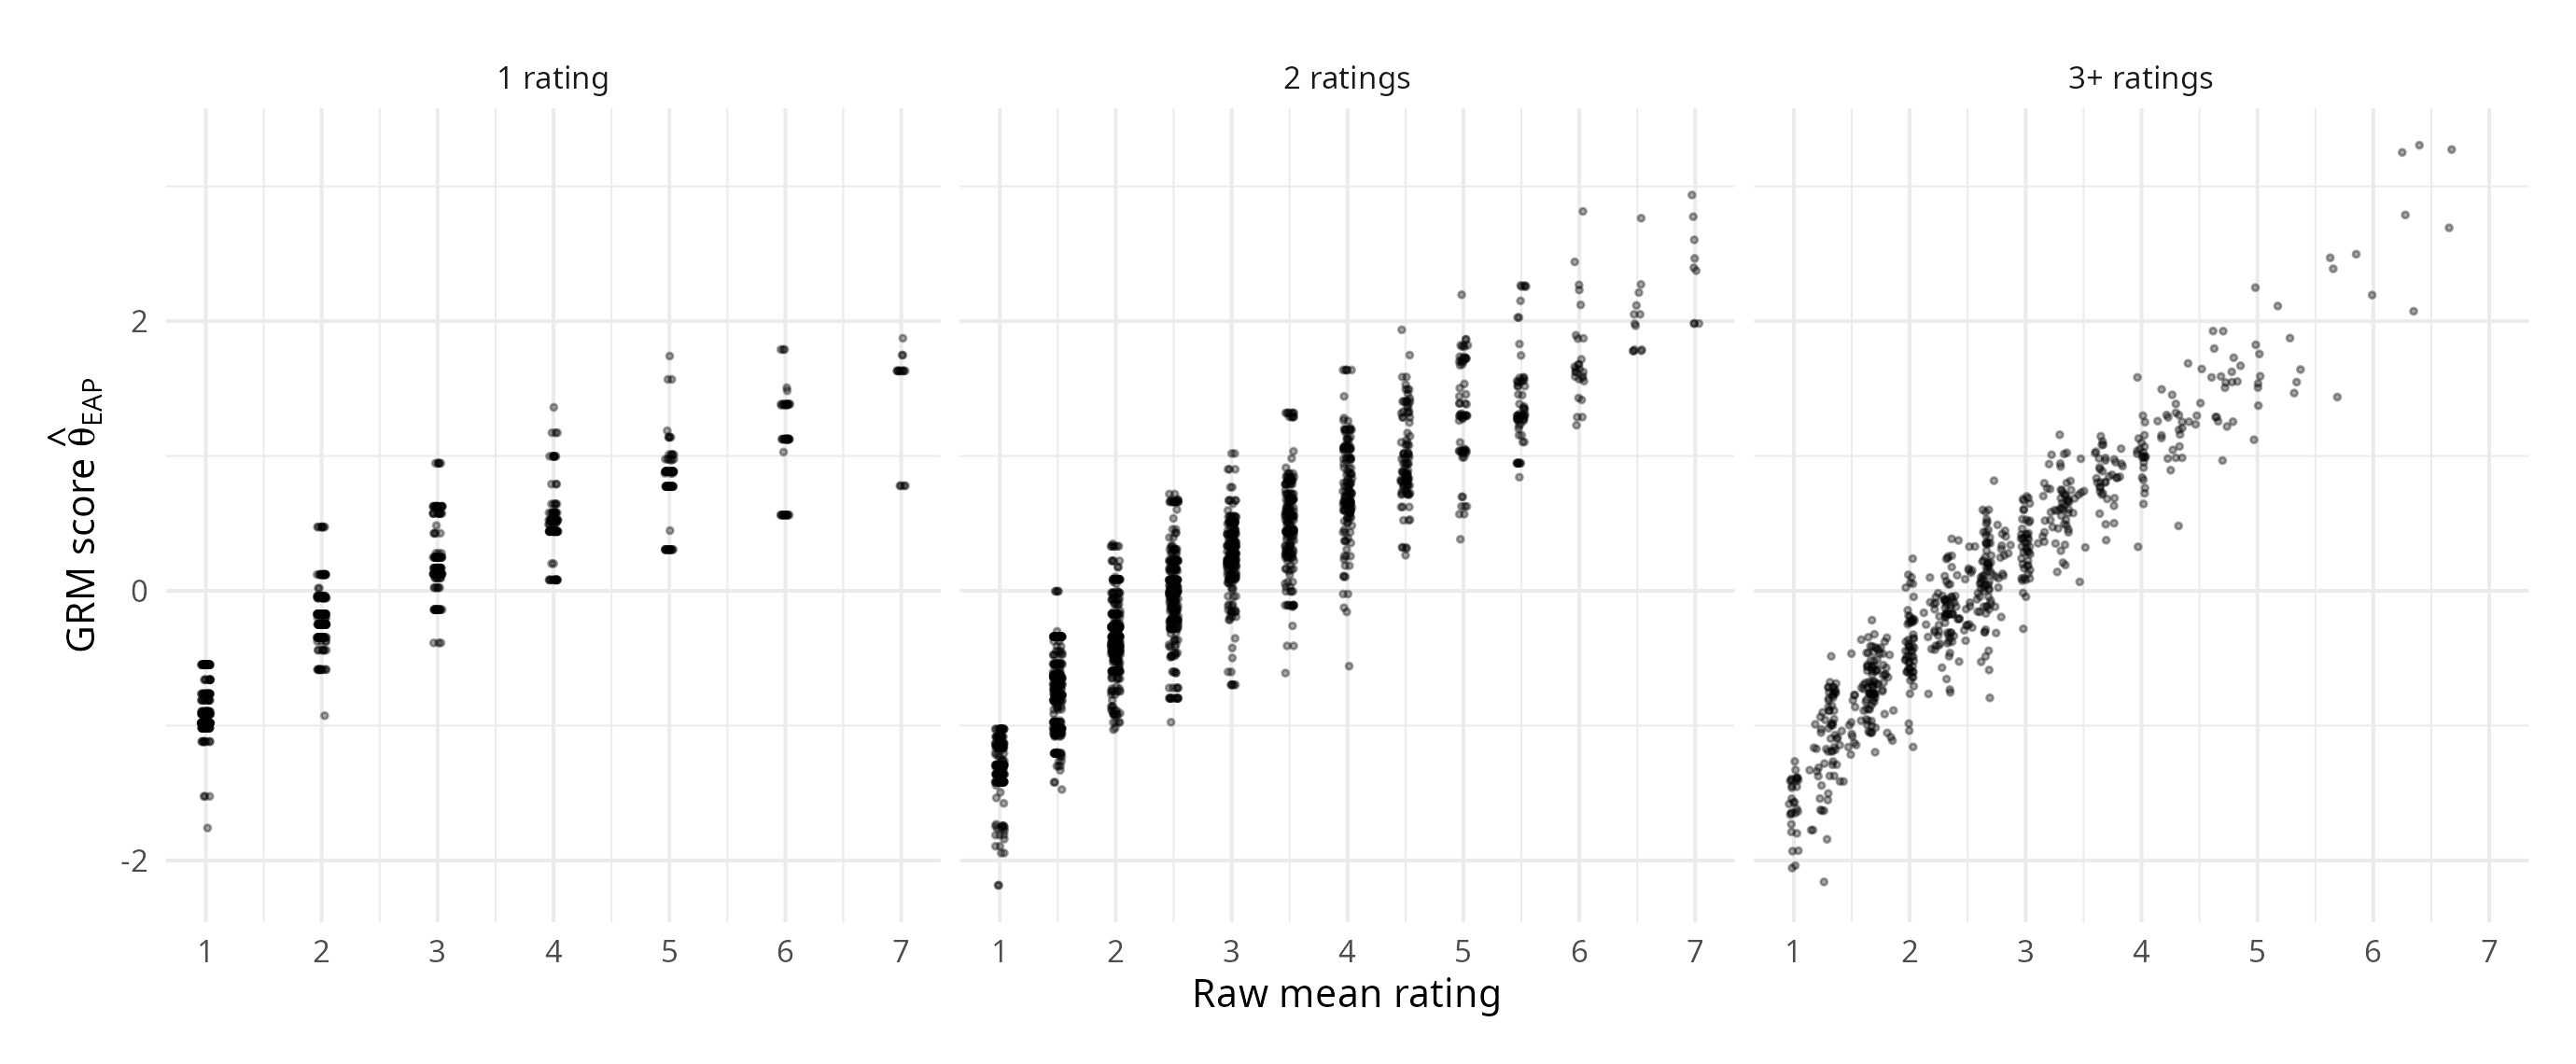

In [32]:
#| label: fig-raw-mean-vs-theta
#| fig-cap: "GRM score (EAP) against the raw mean rating of each product, by number of ratings per product. Points are jittered horizontally."
show_png("grm/figures/grm_raw_mean_vs_theta.png", width=9)

**Sensitivity to the rater exclusion.** The GRM refitted on all raters, including the three with fewer than 15 ratings, compared with the final GRM: reliability, agreement of the product scores, and the discriminations of the common raters.

In [33]:
#| label: tbl-sensitivity-rater-exclusion
#| tbl-cap: "Sensitivity of the GRM results to excluding raters with fewer than 15 ratings: final data versus all raters."
show_table("comparison/sensitivity_rater_exclusion.csv", digits=5)

| Quantity                         | Final data   | All raters   | Note                                          |
|:---------------------------------|:-------------|:-------------|:----------------------------------------------|
| n raters                         | 19           | 22           | –                                             |
| n ratings                        | 7,820        | 7,844        | –                                             |
| n products                       | 3,668        | 3,669        | –                                             |
| excluded raters                  | –            | R20;R21;R22  | –                                             |
| empirical marginal reliability   | 0.67199      | 0.67186      | Var(theta)/(Var(theta)+mean(PSD^2))           |
| model based marginal reliability | 0.95986      | 0.96186      | mirt::marginal_rxx (hypothetical full panel)  |
| theta pearson common products    | 0.99997      | –            | all-raters vs final GRM, 3668 common products |
| theta spearman common products   | 0.99996      | –            | all-raters vs final GRM, 3668 common products |
| theta mean abs diff              | 0.00171      | –            | all-raters vs final GRM, 3668 common products |
| theta max abs diff               | 0.16246      | –            | all-raters vs final GRM, 3668 common products |
| share products changing quintile | 0.00491      | –            | all-raters vs final GRM, 3668 common products |
| a max abs diff common raters     | 0.19820      | –            | all-raters vs final GRM, 19 common raters     |
| a pearson common raters          | 0.99880      | –            | all-raters vs final GRM, 19 common raters     |

In [34]:
#| label: tbl-discrimination-m3
#| tbl-cap: "Rater discriminations in the generalized partial credit model (M3)."
show_table("comparison/discrimination_m3.csv", lambda d: d[["rater_id", "n_ratings", "estimate", "se"]])

| Rater   | Ratings by rater   | Estimate   | SE    |
|:--------|:-------------------|:-----------|:------|
| R09     | 400                | 0.283      | 0.055 |
| R18     | 55                 | 0.312      | 0.145 |
| R17     | 52                 | 0.616      | 0.235 |
| R13     | 254                | 0.863      | 0.159 |
| R11     | 369                | 0.896      | 0.145 |
| R03     | 720                | 0.984      | 0.142 |
| R04     | 620                | 0.992      | 0.184 |
| R07     | 547                | 1.025      | 0.138 |
| R05     | 633                | 1.096      | 0.154 |
| R08     | 522                | 1.102      | 0.195 |
| R02     | 873                | 1.209      | 0.272 |
| R01     | 1,174              | 1.304      | 0.131 |
| R10     | 383                | 1.370      | 0.320 |
| R15     | 73                 | 1.389      | 0.412 |
| R14     | 259                | 1.390      | 0.433 |
| R06     | 520                | 1.942      | 0.385 |
| R19     | 50                 | 2.327      | 1.866 |
| R12     | 264                | 2.383      | 0.680 |
| R16     | 52                 | 2.606      | 1.419 |

Raters whose adjacent-category step parameters are out of order. In adjacent-category models this means that some category is never the most likely response (Andrich, 1978). In the GRM, thresholds are ordered by construction.

In [35]:
#| label: tbl-threshold-order
#| tbl-cap: "Raters with unordered step parameters in M2 (partial-credit MFRM) and M3 (GPCM)."
show_table("comparison/threshold_order.csv", lambda d: d[~d["ordered"]])

| Model                    | Rater   | Steps   | Ordered   | Reversals   | Step parameters                  |
|:-------------------------|:--------|:--------|:----------|:------------|:---------------------------------|
| M2 (partial-credit MFRM) | R03     | 5       | False     | 1           | -0.87;-0.21;1.11;0.69;2.64       |
| M2 (partial-credit MFRM) | R04     | 6       | False     | 1           | -0.54;0.58;0.68;0.52;2.18;3.77   |
| M2 (partial-credit MFRM) | R05     | 6       | False     | 1           | -0.74;0.62;0.58;1.46;1.81;2.72   |
| M2 (partial-credit MFRM) | R06     | 5       | False     | 1           | 0.92;1.26;1.60;2.85;2.38         |
| M2 (partial-credit MFRM) | R11     | 6       | False     | 1           | -0.36;0.96;1.06;0.93;2.65;4.15   |
| M2 (partial-credit MFRM) | R15     | 6       | False     | 2           | -2.18;0.35;0.35;0.15;1.29;3.12   |
| M2 (partial-credit MFRM) | R16     | 6       | False     | 1           | -2.09;0.18;-0.19;1.81;1.87;1.99  |
| M2 (partial-credit MFRM) | R17     | 4       | False     | 2           | 0.49;0.18;1.30;0.98              |
| M2 (partial-credit MFRM) | R19     | 6       | False     | 2           | -0.43;-0.85;0.10;-0.29;1.21;1.76 |
| M3 (GPCM)                | R03     | 5       | False     | 1           | -0.82;-0.19;1.11;0.65;2.59       |
| M3 (GPCM)                | R04     | 6       | False     | 1           | -0.53;0.58;0.66;0.48;2.13;3.69   |
| M3 (GPCM)                | R05     | 6       | False     | 1           | -0.69;0.57;0.56;1.38;1.72;2.57   |
| M3 (GPCM)                | R06     | 5       | False     | 1           | 0.51;1.06;1.46;2.30;2.27         |
| M3 (GPCM)                | R09     | 6       | False     | 2           | -0.43;-0.78;0.63;-0.12;1.10;3.92 |
| M3 (GPCM)                | R11     | 6       | False     | 1           | -0.29;1.09;1.14;0.94;2.78;4.31   |
| M3 (GPCM)                | R15     | 6       | False     | 1           | -1.90;0.21;0.34;0.28;1.20;2.81   |
| M3 (GPCM)                | R17     | 4       | False     | 2           | 1.12;0.22;1.74;0.83              |
| M3 (GPCM)                | R18     | 5       | False     | 1           | -7.29;-2.14;0.42;-0.70;5.02      |

Infit and outfit under M1, the fit statistics usually reported for many-facet Rasch models (Eckes, 2015).

In [36]:
#| label: tbl-rater-fit-m1
#| tbl-cap: "Rater infit and outfit mean squares under M1 (rating-scale MFRM)."
show_table("comparison/rater_fit_m1.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit"]])

| Rater   | Ratings by rater   | Infit   | Outfit   |
|:--------|:-------------------|:--------|:---------|
| R01     | 1,174              | 0.466   | 0.481    |
| R02     | 873                | 0.786   | 0.782    |
| R03     | 720                | 0.579   | 0.579    |
| R04     | 620                | 0.687   | 0.660    |
| R05     | 633                | 0.701   | 0.669    |
| R06     | 520                | 0.909   | 0.705    |
| R07     | 547                | 0.826   | 0.751    |
| R08     | 522                | 0.540   | 0.548    |
| R09     | 400                | 0.978   | 0.958    |
| R10     | 383                | 0.407   | 0.389    |
| R11     | 369                | 0.938   | 0.874    |
| R12     | 264                | 0.238   | 0.255    |
| R13     | 254                | 0.405   | 0.406    |
| R14     | 259                | 0.747   | 0.695    |
| R15     | 73                 | 0.753   | 0.698    |
| R16     | 52                 | 0.452   | 0.457    |
| R17     | 52                 | 1.328   | 1.190    |
| R18     | 55                 | 1.009   | 1.071    |
| R19     | 50                 | 0.654   | 0.701    |

Marginal reliability (hypothetical full panel) and empirical reliability (actual scores) for each model.

In [37]:
#| label: tbl-marginal-reliability-models
#| tbl-cap: "Marginal and empirical reliability by model, for comparison."
show_table("comparison/marginal_reliability.csv")

| Model                    | Latent variance   | Marginal reliability   | marginal_rxx (mirt)   | Empirical reliability   |
|:-------------------------|:------------------|:-----------------------|:----------------------|:------------------------|
| M1 (rating-scale MFRM)   | 0.962             | 0.943                  | –                     | 0.626                   |
| M2 (partial-credit MFRM) | 1.087             | 0.944                  | –                     | 0.637                   |
| M3 (GPCM)                | 1                 | 0.955                  | 0.955                 | 0.657                   |
| GRM                      | 1                 | 0.960                  | 0.960                 | 0.672                   |

## 5. Naive indices and overview

**Naive indices** are reference values for common practice. They are not used downstream.
- **Cronbach's α** (Cronbach, 1951) measures the consistency of the unweighted rater mean. It assumes τ-equivalent raters and complete data, so here it is computed from pairwise covariances and on the largest fully crossed block.
- **Krippendorff's α** (ordinal; Hayes & Krippendorff, 2007) measures the agreement of single ratings, treating raters as interchangeable. Confidence intervals for both come from a bootstrap over products. For the pairwise Cronbach's α, replications in which some rater pair loses all shared products cannot be computed; the interval uses the remaining replications and is approximate (Failed replications in the table).

In [38]:
def naive_indices():
    cr, ka = read_res("naive/cronbach_alpha.csv"), read_res("naive/krippendorff_alpha.csv")
    if cr is None or ka is None:
        return None
    return pd.concat([
        pd.DataFrame({"index": "Cronbach's alpha: " + cr["variant"], "value": cr["raw_alpha"],
                      "ci_low": cr.get("ci_low"), "ci_high": cr.get("ci_high"), "n_raters": cr["n_raters"],
                      "n_products": cr["n_products_contributing"],
                      "n_boot": cr.get("n_boot"), "n_boot_failed": cr.get("n_boot_failed")}),
        pd.DataFrame({"index": "Krippendorff's alpha (ordinal)", "value": ka["alpha"],
                      "ci_low": ka["ci_low"], "ci_high": ka["ci_high"], "n_raters": ka["n_raters"],
                      "n_products": ka["n_pairable_units"],
                      "n_boot": ka.get("n_boot"), "n_boot_failed": ka.get("n_boot_failed")}),
    ], ignore_index=True)

In [39]:
#| label: tbl-naive-indices
#| tbl-cap: "Cronbach's alpha (consistency of the unweighted rater mean) and Krippendorff's alpha (ordinal agreement of single ratings), each with a 95% bootstrap CI over products (1,000 replications). For the pairwise Cronbach's alpha, replications in which a rater pair lost all shared products could not be computed (Failed replications); its CI is approximate."
_naive = naive_indices()
_missing("naive/*.csv") if _naive is None else Markdown(pretty_headers(tidy(_naive)).to_markdown(index=False, disable_numparse=True))

| Index                                                     | Value   | 95% CI lower   | 95% CI upper   | Raters   | Products   | Bootstrap replications   | Failed replications   |
|:----------------------------------------------------------|:--------|:---------------|:---------------|:---------|:-----------|:-------------------------|:----------------------|
| Cronbach's alpha: pairwise covariances, all usable raters | 0.928   | 0.891          | 0.943          | 14       | 1,900      | 1,000                    | 361                   |
| Cronbach's alpha: fully crossed block (listwise complete) | 0.658   | 0.526          | 0.756          | 3        | 139        | 1,000                    | 0                     |
| Krippendorff's alpha (ordinal)                            | 0.392   | 0.362          | 0.417          | 19       | 2,771      | 1,000                    | 0                     |

**Overview.** All indices side by side, with what each refers to. They answer different questions: the reliability of the actual scores, of a hypothetical full panel, or of single ratings. They are not interchangeable.

In [40]:
#| label: tbl-reliability-overview
#| tbl-cap: "Overview of the reliability and agreement indices and what each refers to."
show_table("summary/reliability_overview.csv")

| Index                                          | Refers to                                                 | Value   | CI or note                                                                                                                   |
|:-----------------------------------------------|:----------------------------------------------------------|:--------|:-----------------------------------------------------------------------------------------------------------------------------|
| Krippendorff's alpha (ordinal)                 | consensus of single ratings                               | 0.392   | 95% bootstrap CI [0.362, 0.417], 1000 replications                                                                           |
| Cronbach's alpha (pairwise covariances)        | consistency of the unweighted rater mean                  | 0.928   | 95% CI [0.891, 0.943] (bootstrap, 639 of 1000 replications computable, approximate); 14 raters; removed: R19;R14;R02;R16;R12 |
| Cronbach's alpha (fully crossed block)         | consistency of the unweighted rater mean (crossed subset) | 0.658   | 95% CI [0.526, 0.756] (bootstrap, 1000 replications); 3 raters, 139 products                                                 |
| GRM: empirical marginal reliability            | actual theta_hat (primary)                                | 0.672   | 95% CI [0.649, 0.687] (200 parameter draws); Var(theta)/(Var(theta)+mean(PSD^2))                                             |
| GRM: model-based marginal reliability          | hypothetical full panel                                   | 0.960   | 95% CI [0.953, 0.968] (200 parameter draws); mirt::marginal_rxx, all raters                                                  |
| GRM: median rel_post                           | precision per product                                     | 0.698   | Q1 0.596, Q3 0.769                                                                                                           |
| GRM: IQR rel_post                              | precision per product                                     | 0.173   | –                                                                                                                            |
| M1 (rating-scale MFRM): marginal reliability   | comparison                                                | 0.943   | –                                                                                                                            |
| M2 (partial-credit MFRM): marginal reliability | comparison                                                | 0.944   | –                                                                                                                            |
| M3 (GPCM): marginal reliability                | comparison                                                | 0.955   | –                                                                                                                            |

## References

- Andrich, D. (1978). A rating formulation for ordered response categories. *Psychometrika, 43*(4), 561–573.
- Cai, L., & Monroe, S. (2014). *A new statistic for evaluating item response theory models for ordinal data* (CRESST Report 839). University of California, Los Angeles.
- Chalmers, R. P. (2012). mirt: A multidimensional item response theory package for the R environment. *Journal of Statistical Software, 48*(6), 1–29.
- Christensen, K. B., Makransky, G., & Horton, M. (2017). Critical values for Yen's Q3: Identification of local dependence in the Rasch model using residual correlations. *Applied Psychological Measurement, 41*(3), 178–194.
- Cronbach, L. J. (1951). Coefficient alpha and the internal structure of tests. *Psychometrika, 16*(3), 297–334.
- Eckes, T. (2015). *Introduction to many-facet Rasch measurement* (2nd ed.). Peter Lang.
- Green, B. F., Bock, R. D., Humphreys, L. G., Linn, R. L., & Reckase, M. D. (1984). Technical guidelines for assessing computerized adaptive tests. *Journal of Educational Measurement, 21*(4), 347–360.
- Hayes, A. F., & Krippendorff, K. (2007). Answering the call for a standard reliability measure for coding data. *Communication Methods and Measures, 1*(1), 77–89.
- Kang, T., & Chen, T. T. (2008). Performance of the generalized S-X² item fit index for polytomous IRT models. *Journal of Educational Measurement, 45*(4), 391–406.
- Linacre, J. M. (1989). *Many-facet Rasch measurement*. MESA Press.
- Masters, G. N. (1982). A Rasch model for partial credit scoring. *Psychometrika, 47*(2), 149–174.
- Muraki, E. (1992). A generalized partial credit model: Application of an EM algorithm. *Applied Psychological Measurement, 16*(2), 159–176.
- Myszkowski, N., & Storme, M. (2019). Judge response theory? A call to upgrade our psychometrical account of creativity judgments. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 167–175.
- Orlando, M., & Thissen, D. (2000). Likelihood-based item-fit indices for dichotomous item response theory models. *Applied Psychological Measurement, 24*(1), 50–64.
- Primi, R., Silvia, P. J., Jauk, E., & Benedek, M. (2019). Applying many-facet Rasch modeling in the assessment of creativity. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 176–186.
- Samejima, F. (1969). Estimation of latent ability using a response pattern of graded scores. *Psychometrika Monograph Supplement*, No. 17.
- Wright, B. D., & Masters, G. N. (1982). *Rating scale analysis*. MESA Press.
- Yen, W. M. (1984). Effects of local item dependence on the fit and equating performance of the three-parameter logistic model. *Applied Psychological Measurement, 8*(2), 125–145.